### **🎯Business Understanding**

The Fraud Prevention department of a financial institution has an established process for identifying and evaluating suspicious transactions. However, the increasing volume of transactions has made the predominantly manual process inefficient and difficult to scale.

This challenge creates two major business risks: financial losses resulting from fraudulent transactions that are not detected in time, and a negative impact on the customer experience when legitimate transactions are incorrectly flagged or blocked.

To address these challenges, the institution aims to leverage Machine Learning to automate the identification of potentially fraudulent transactions, improving operational efficiency, detection accuracy, and decision-making.

**Business Objective**

The objective of this project is to explore historical transaction data and develop a predictive classification model capable of identifying transactions as either *fraudulent* or *non-fraudulent*.

The model is expected to support the fraud prevention process by:

- Improving the identification of potentially fraudulent transactions.
- Reducing financial losses associated with undetected fraud.
- Minimizing false positives that may affect legitimate customers.
- Increasing the scalability and efficiency of transaction monitoring.

**Data Mining Goal**

Explore the available historical transaction dataset, which contains previously labeled fraudulent transactions, perform data analysis and preprocessing, and develop and evaluate a Machine Learning classification model to distinguish between fraudulent and legitimate transactions.

The final results will be presented through clear and objective performance metrics, providing insights into the model's effectiveness and its potential business value.

In [34]:
# Libraries

# Data manipulation
import pandas as pd
import numpy as np 

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import math
from matplotlib.ticker import PercentFormatter
from scipy.stats import pointbiserialr
import plotly.express as px

# Machine learning model
from sklearn.model_selection import (
     train_test_split,
     StratifiedKFold,
     cross_validate,
     cross_val_predict)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    PolynomialFeatures,
    SplineTransformer
)

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    precision_recall_curve,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

from sklearn.base import clone

In [35]:
# Color dictionary for data visualization
cores = {True: '#e74c3c', False:'#2ecc71'}

### **🔎 Data Understanding**

In [36]:
# Loading dataset that will be used to build the machine learning model
df1 = pd.read_csv('transacoes_historico_2025.csv')

df1.head(5)


,datahora_transacao,nome_estabelecimento,tipo_estabelecimento,valor_transacao,nome_cliente,cidade,flag_fraude,device_type,is_new_device,temperatura_celsius,codigo_postal,score_interno,turno,valor_categoria,cidade_regiao
0,2025-01-01 00:00:00,Pharmacy Z,Pharmacy,9.12,Cliente_16621,Recife,False,desktop,False,31.5,72519-282,562,madrugada,baixo,Nordeste
1,2025-01-01 00:01:00,Supermarket A,Supermarket,37.74,Cliente_12596,Recife,False,mobile,False,28.1,43549-179,461,madrugada,medio,Nordeste
2,2025-01-01 00:02:00,Restaurant Y,Food & Beverage,30.94,Cliente_10474,Salvador,False,mobile,True,29.1,68582-277,577,madrugada,medio,Nordeste
3,2025-01-01 00:03:00,Gas Station,Fuel,41.72,Cliente_20661,Salvador,False,mobile,True,28.6,21497-208,666,madrugada,medio,Nordeste
4,2025-01-01 00:04:00,Online Shop 2,E-commerce,13.85,Cliente_4018,Rio de Janeiro,False,mobile,False,30.2,50814-648,892,madrugada,baixo,Sudeste


In [37]:
# Loading the dataset for which predictions are required
df2 = pd.read_csv('transacoes_jan2026.csv')
df2.head(5)

,datahora_transacao,nome_estabelecimento,tipo_estabelecimento,valor_transacao,nome_cliente,cidade,device_type,is_new_device,temperatura_celsius,codigo_postal,score_interno,turno,valor_categoria,cidade_regiao
0,2026-01-01 00:00:00,Pharmacy Z,Pharmacy,21.72,Cliente_16241,Curitiba,desktop,False,17.4,36135-417,691,madrugada,baixo,Sul
1,2026-01-01 00:01:00,Electronics Store,Retail,28.70,Cliente_10027,Porto Alegre,mobile,False,11.9,83134-620,292,madrugada,baixo,Sul
2,2026-01-01 00:02:00,Restaurant X,Food & Beverage,34.55,Cliente_13606,Porto Alegre,desktop,False,15.0,41309-759,81,madrugada,medio,Sul
3,2026-01-01 00:03:00,Gas Station,Fuel,57.53,Cliente_7302,Belo Horizonte,desktop,False,23.5,15793-404,54,madrugada,medio,Sudeste
4,2026-01-01 00:04:00,Gas Station,Fuel,149.50,Cliente_20061,Recife,desktop,False,28.1,73917-730,31,madrugada,alto,Nordeste


In [38]:
# Exploring the dataset structure
print("DATA INFORMATION".center(50))
print("="*50)

print(df1.info())

print("="*50)
print("DATA SHAPE".center(50))
print("="*50)

print(f'Rows: {df1.shape[0]}')
print(f'Columns: {df1.shape[1]}')

                 DATA INFORMATION                 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 523525 entries, 0 to 523524
Data columns (total 15 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   datahora_transacao    523525 non-null  object 
 1   nome_estabelecimento  523525 non-null  object 
 2   tipo_estabelecimento  523525 non-null  object 
 3   valor_transacao       523525 non-null  float64
 4   nome_cliente          523525 non-null  object 
 5   cidade                523525 non-null  object 
 6   flag_fraude           523525 non-null  bool   
 7   device_type           523525 non-null  object 
 8   is_new_device         523525 non-null  bool   
 9   temperatura_celsius   523525 non-null  float64
 10  codigo_postal         523525 non-null  object 
 11  score_interno         523525 non-null  int64  
 12  turno                 523525 non-null  object 
 13  valor_categoria       523525 non-null  object 
 14  c

In [39]:
# Dataset statistics
display(df1.describe())
print("="*152)
display(df1.describe(include='object'))

,valor_transacao,temperatura_celsius,score_interno
count,523525.000000,523525.000000,523525.000000
mean,43.962948,24.005198,500.373539
std,74.408984,6.921326,288.921133
min,0.500000,-12.700000,0.000000
25%,14.260000,19.500000,250.000000
50%,25.250000,25.200000,500.000000
75%,44.950000,29.200000,751.000000
max,722.900000,46.100000,1000.000000


,datahora_transacao,nome_estabelecimento,tipo_estabelecimento,nome_cliente,cidade,device_type,codigo_postal,turno,valor_categoria,cidade_regiao
count,523525,523525,523525,523525,523525,523525,523525,523525,523525,523525
unique,523525,10,6,26214,7,3,521905,4,3,3
top,2025-01-01 00:00:00,Online Shop 2,E-commerce,Cliente_7385,Curitiba,mobile,52584-785,manha,baixo,Sudeste
freq,1,52853,105223,44,75116,291056,3,130928,304015,224124


### **🔎📄 Summary of the Data Understanding**

#### Initial Data Assessment

During the initial data assessment, no missing values were identified in the dataset. The dataset consists of **523,525 observations and 15 features**, providing a substantial volume of transactional data for the development of a machine learning model focused on fraud detection.

**Next Activity: In-Depth Exploratory Data Analysis (EDA)**

The next phase will focus on a more detailed investigation of feature distributions, correlations, outliers, fraud prevalence, and behavioral differences between legitimate and fraudulent transactions. These analyses will support informed decisions during data preparation, feature engineering, and model development.



### **In-Depth Exploratory Data Analysis (EDA)**

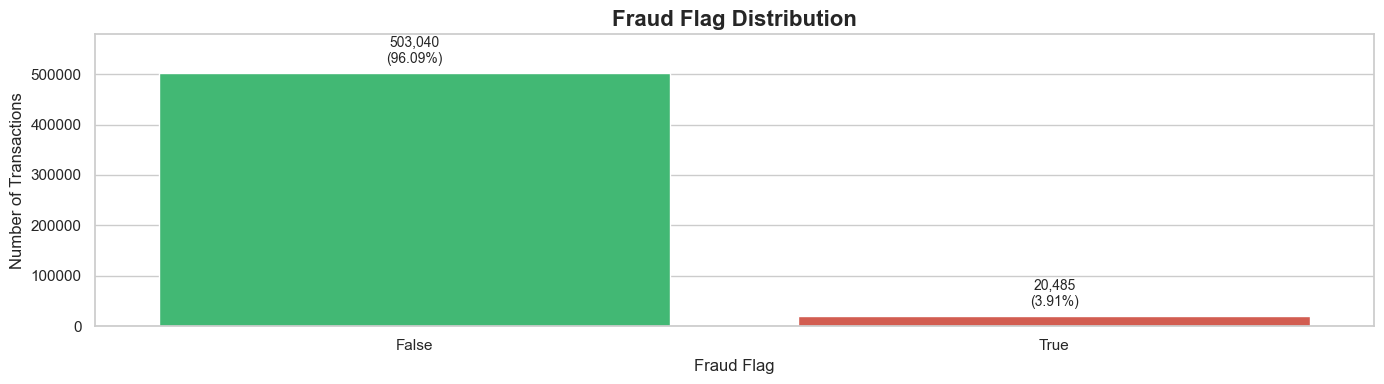

In [40]:
fig, ax = plt.subplots(figsize=(14, 4))

sns.countplot(
    data=df1,
    x='flag_fraude',
    hue='flag_fraude',
    palette=cores,
    legend=False,
    ax=ax
)

total = len(df1)

for container in ax.containers:
    labels = [
        f'{int(bar.get_height()):,}\n({bar.get_height()/total:.2%})'
        for bar in container
    ]
    ax.bar_label(container, labels=labels, padding=5, fontsize=10)

ax.set_title(
    'Fraud Flag Distribution',
    fontsize=16,
    fontweight='bold'
)

ax.set_xlabel('Fraud Flag')
ax.set_ylabel('Number of Transactions')

ax.margins(y=0.15)

plt.tight_layout()
plt.show()

#### **Target Variable Distribution: Class Imbalance**

The analysis of the target variable (`flag_fraude`) revealed a significant class imbalance within the dataset.

Of the 523,525 transactions, 503,040 (96.09%) were classified as legitimate, while 20,485 (3.91%) were identified as fraudulent. This corresponds to an approximate class ratio of 24.56:1.

This distribution represents an important consideration for the development of the fraud detection model, as the predominance of legitimate transactions may bias classification algorithms toward the majority class.

Consequently, accuracy alone will not be considered a sufficient performance metric. Additional evaluation metrics, including Precision, Recall, F1-score, and Precision-Recall AUC (PR-AUC), will be prioritized to assess the model's ability to identify fraudulent transactions effectively.

During the modeling phase, different strategies for handling class imbalance, such as class weighting, resampling techniques, and decision threshold optimization, will be evaluated.

Further exploratory analysis will investigate fraud rates across transaction categories, geographical regions, devices, transaction amounts, and time periods to identify potential patterns associated with fraudulent behavior.

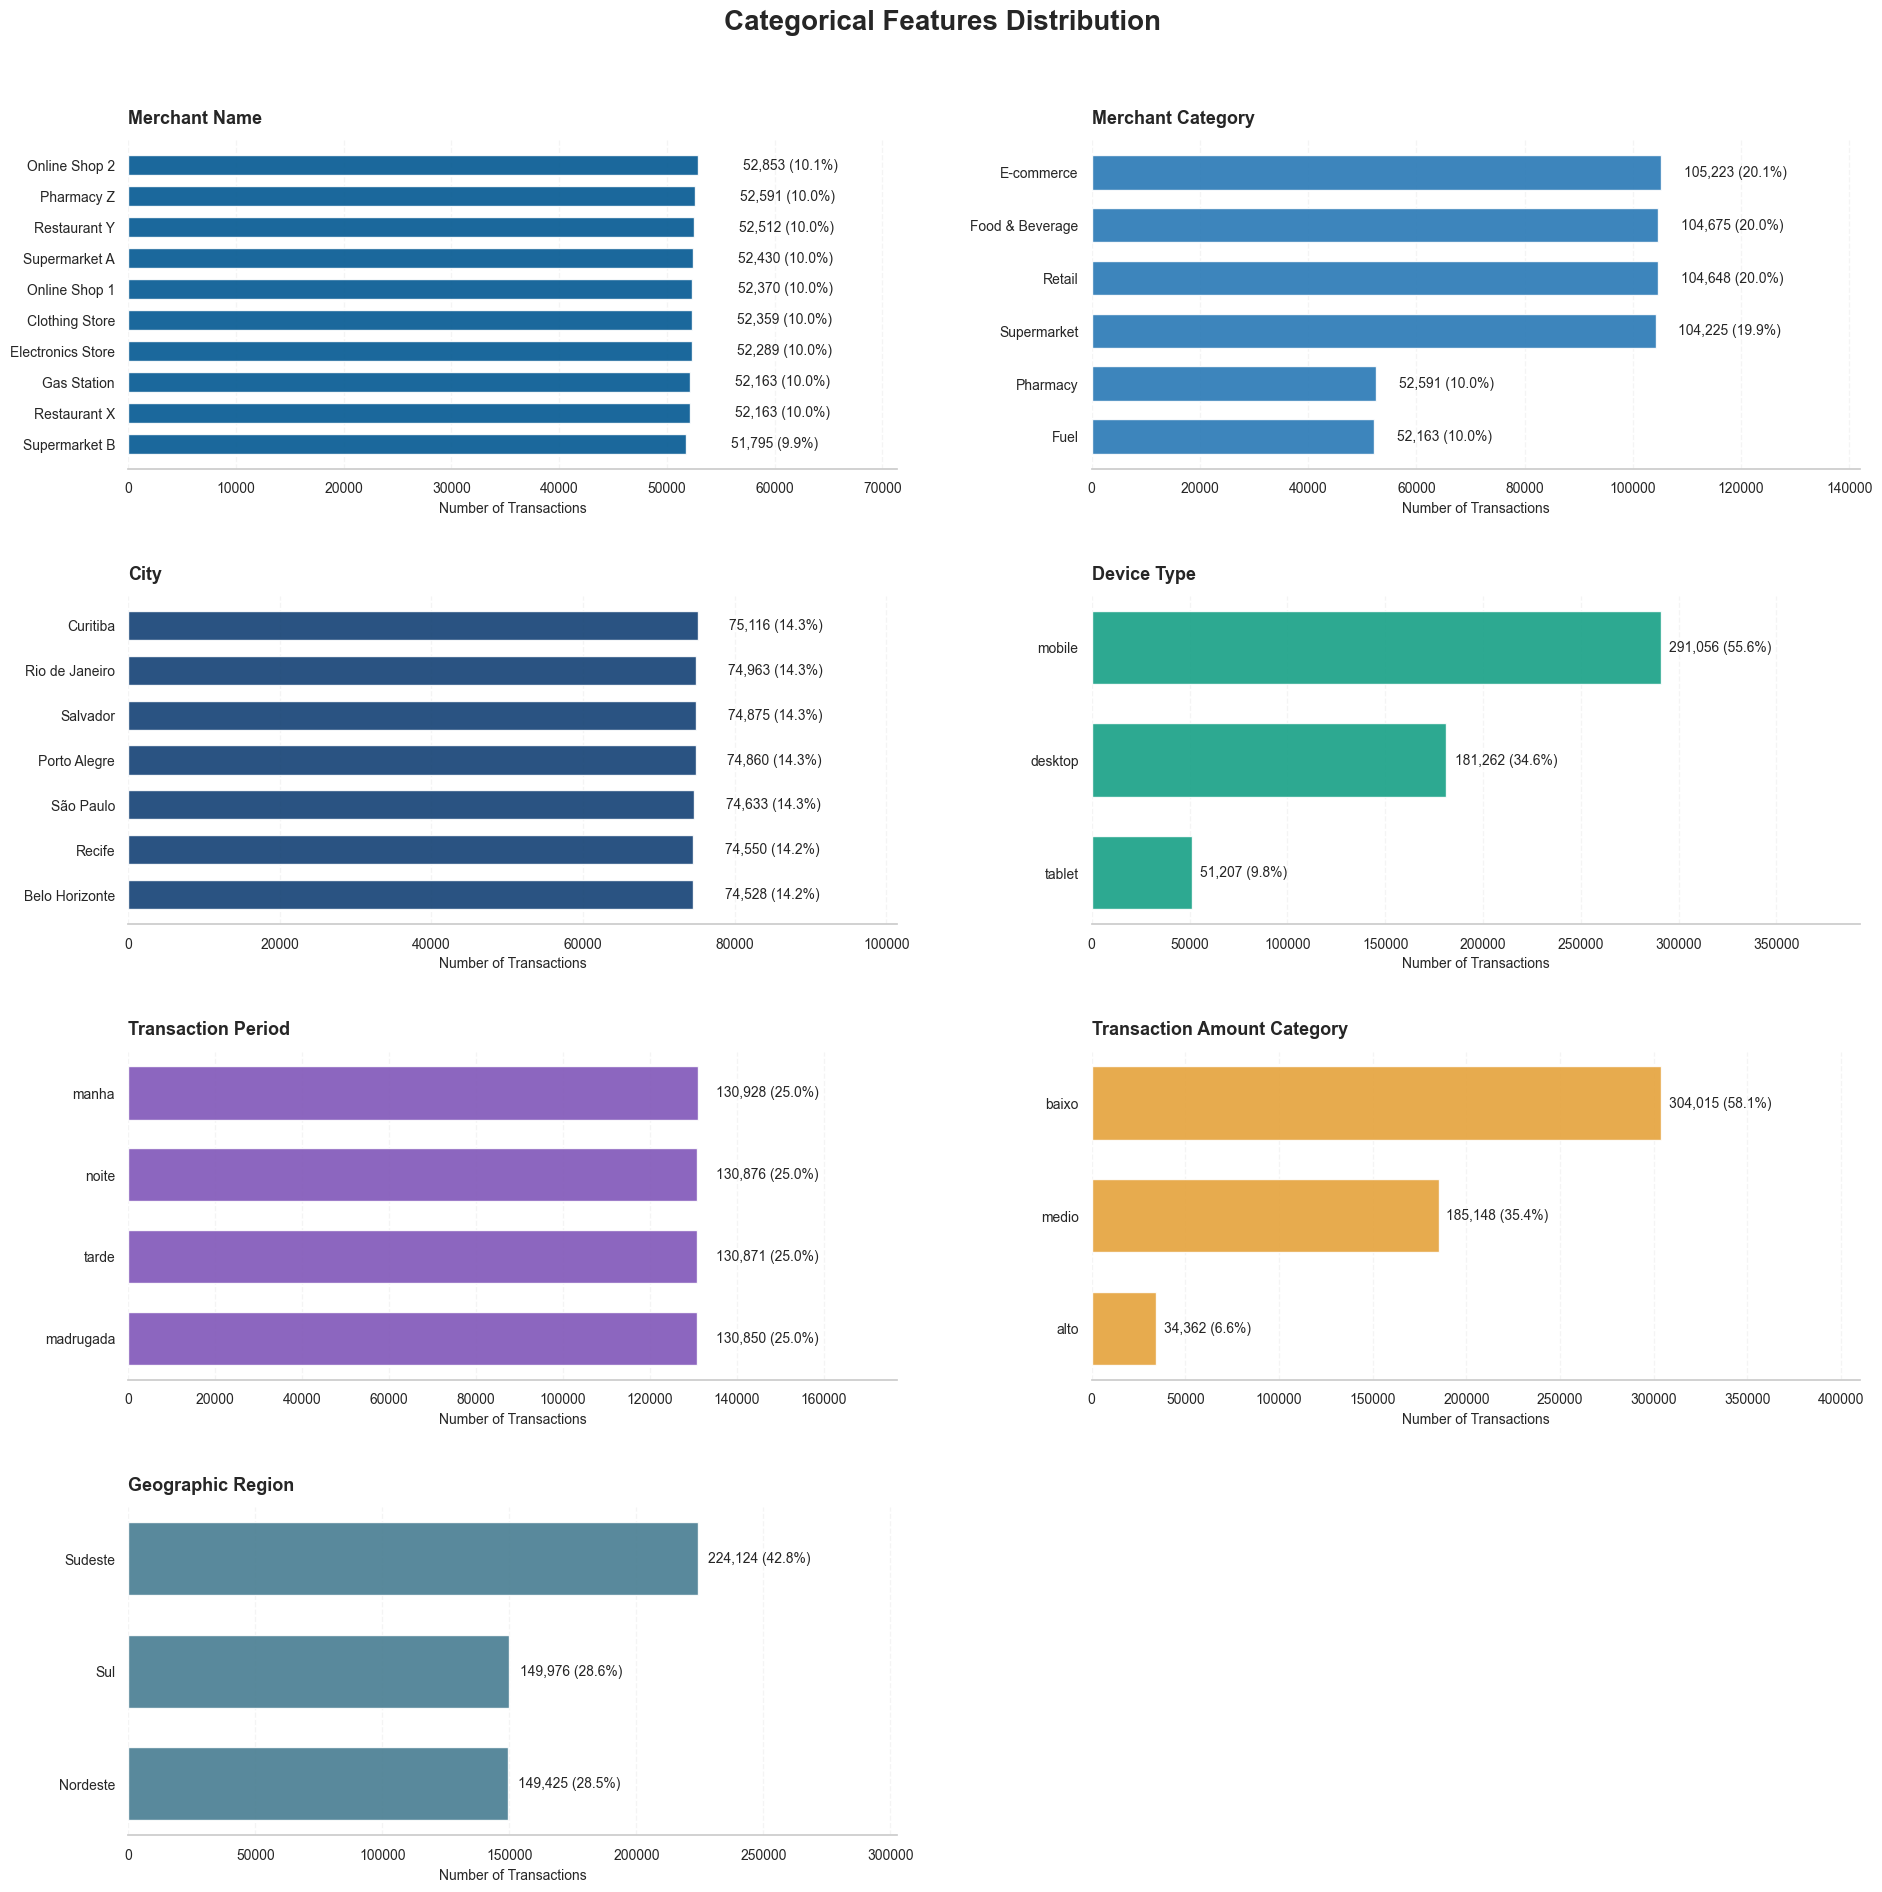

In [41]:
# Categorical features
categorical_features = [
    'nome_estabelecimento',
    'tipo_estabelecimento',
    'cidade',
    'device_type',
    'turno',
    'valor_categoria',
    'cidade_regiao'
]

# English titles
feature_titles = {
    'nome_estabelecimento': 'Merchant Name',
    'tipo_estabelecimento': 'Merchant Category',
    'cidade': 'City',
    'device_type': 'Device Type',
    'turno': 'Transaction Period',
    'valor_categoria': 'Transaction Amount Category',
    'cidade_regiao': 'Geographic Region'
}

# Color palette
colors = [
    '#025891',
    '#2878B5',
    '#134074',
    '#16A085',
    '#8055B8',
    '#E5A23B',
    '#477C91'
]

# Dashboard configuration
n_cols = 2
n_rows = math.ceil(len(categorical_features) / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(19, 19)
)

axes = axes.flatten()

sns.set_style("whitegrid")

# Plot categorical distributions
for i, col in enumerate(categorical_features):

    ax = axes[i]

    counts = df1[col].value_counts(dropna=False)
    total = counts.sum()

    labels = counts.index.astype(str)
    values = counts.values

    # Horizontal bars
    bars = ax.barh(
        labels,
        values,
        color=colors[i],
        alpha=0.90,
        height=0.65
    )

    # Absolute values and percentages
    for bar, value in zip(bars, values):

        percentage = (value / total) * 100

        ax.text(
            bar.get_width() + total * 0.008,
            bar.get_y() + bar.get_height() / 2,
            f'{value:,.0f} ({percentage:.1f}%)',
            va='center',
            ha='left',
            fontsize=10,
            fontweight='medium'
        )

    # Sort highest to lowest
    ax.invert_yaxis()

    # Titles
    ax.set_title(
        feature_titles[col],
        fontsize=13,
        fontweight='bold',
        loc='left',
        pad=12
    )

    ax.set_xlabel('Number of Transactions', fontsize=10)
    ax.set_ylabel('')

    # Space for labels
    ax.set_xlim(0, max(values) * 1.35)

    # Visual styling
    ax.grid(
        axis='x',
        linestyle='--',
        alpha=0.20
    )

    ax.grid(axis='y', visible=False)

    ax.spines[['top', 'right', 'left']].set_visible(False)

    ax.tick_params(axis='both', labelsize=10)

# Remove unused axes
for j in range(len(categorical_features), len(axes)):
    fig.delaxes(axes[j])

# Main title
fig.suptitle(
    'Categorical Features Distribution',
    fontsize=20,
    fontweight='bold',
    y=0.995
)

plt.tight_layout(
    rect=[0, 0, 1, 0.975],
    h_pad=3,
    w_pad=4
)

plt.show()

#### **📊📃Univariate Analysis: Key Findings**

The categorical analysis revealed relatively balanced distributions across merchants, cities, and transaction periods. Mobile devices account for 55.6% of transactions, while low-value transactions predominate (58.1%). Geographically, the Southeast region has the highest concentration (42.8%). These findings provide an initial overview of transaction patterns and support further investigation during bivariate analysis.

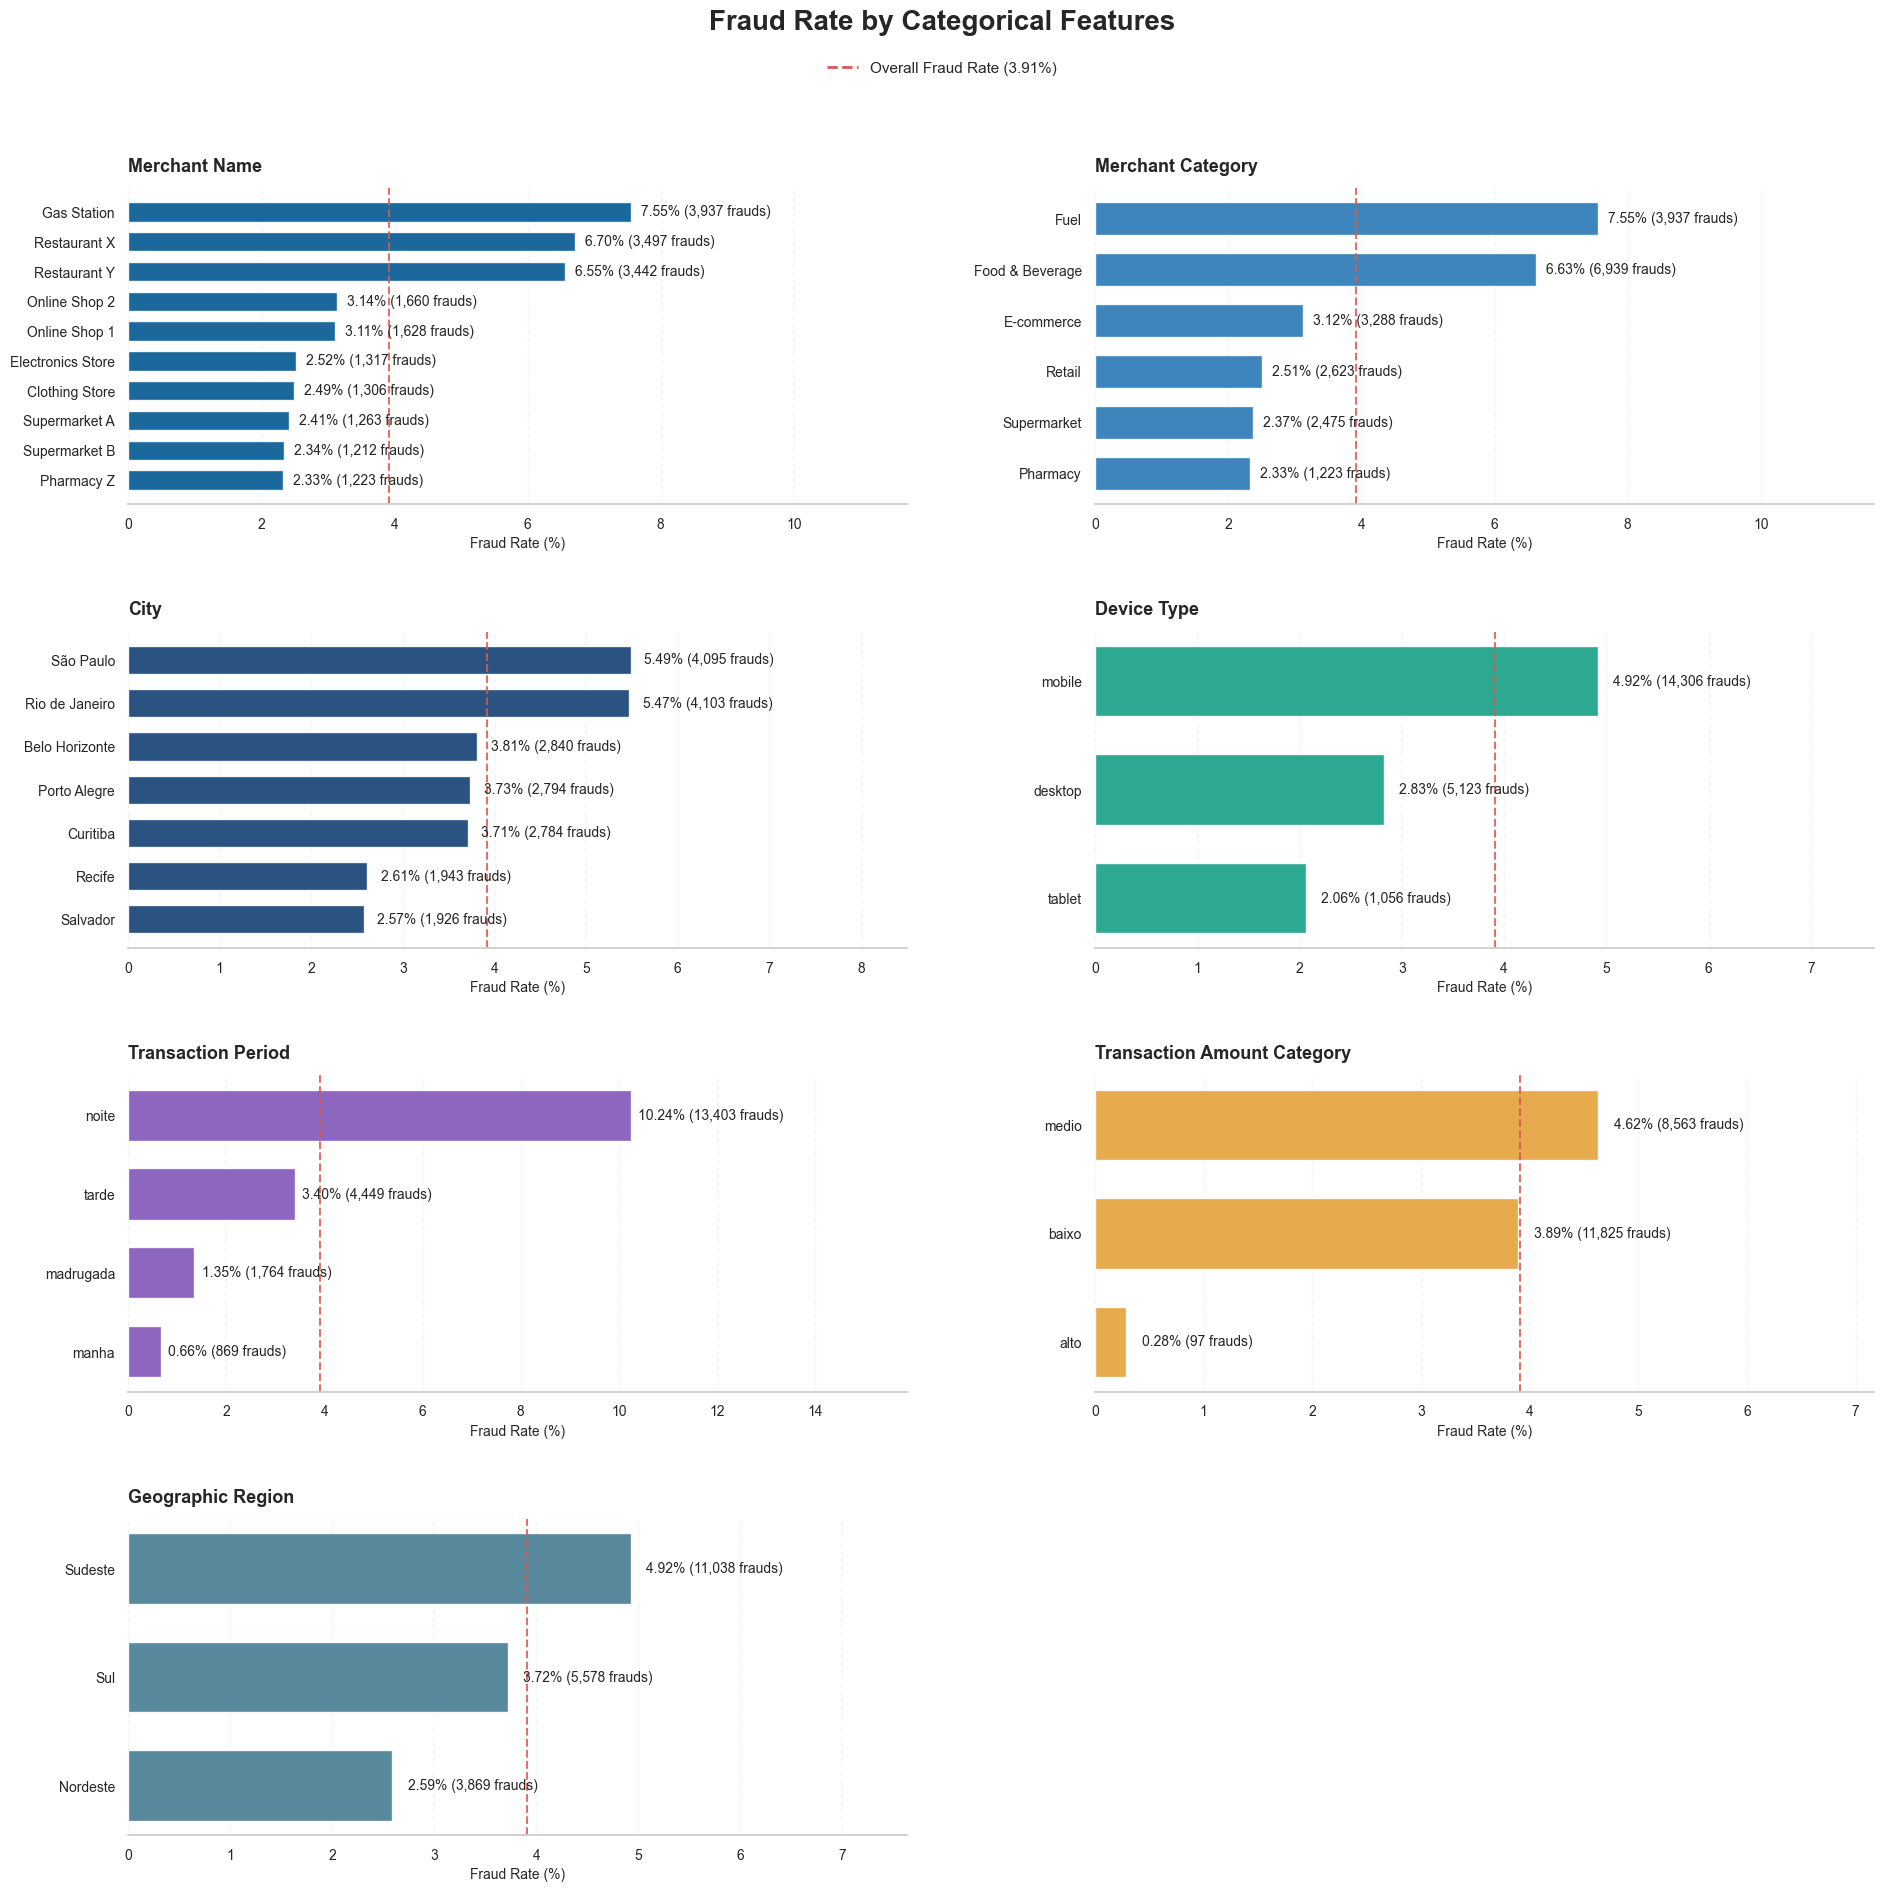

In [42]:
# Categorical features
categorical_features = [
    'nome_estabelecimento',
    'tipo_estabelecimento',
    'cidade',
    'device_type',
    'turno',
    'valor_categoria',
    'cidade_regiao'
]

# English titles
feature_titles = {
    'nome_estabelecimento': 'Merchant Name',
    'tipo_estabelecimento': 'Merchant Category',
    'cidade': 'City',
    'device_type': 'Device Type',
    'turno': 'Transaction Period',
    'valor_categoria': 'Transaction Amount Category',
    'cidade_regiao': 'Geographic Region'
}

# Color palette
colors = [
    '#025891',
    '#2878B5',
    '#134074',
    '#16A085',
    '#8055B8',
    '#E5A23B',
    '#477C91'
]

# Dashboard configuration
n_cols = 2
n_rows = math.ceil(len(categorical_features) / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(19, 19)
)

axes = axes.flatten()

sns.set_style("whitegrid")

# Overall fraud rate
overall_fraud_rate = df1['flag_fraude'].mean() * 100

for i, col in enumerate(categorical_features):

    ax = axes[i]

    # Cross-tabulation summary
    summary = (
        df1.groupby(col, dropna=False)['flag_fraude']
        .agg(
            total='count',
            frauds='sum',
            fraud_rate='mean'
        )
        .reset_index()
    )

    summary['fraud_rate'] *= 100

    # Sort by fraud rate
    summary = summary.sort_values(
        'fraud_rate',
        ascending=False
    )

    labels = summary[col].fillna('Missing').astype(str)
    values = summary['fraud_rate'].values

    # Horizontal bars
    bars = ax.barh(
        labels,
        values,
        color=colors[i],
        alpha=0.90,
        height=0.65
    )

    # Fraud rate and absolute fraud count
    for bar, rate, frauds in zip(
        bars,
        summary['fraud_rate'],
        summary['frauds']
    ):

        ax.text(
            bar.get_width() + 0.15,
            bar.get_y() + bar.get_height() / 2,
            f'{rate:.2f}% ({frauds:,.0f} frauds)',
            va='center',
            ha='left',
            fontsize=10
        )

    # Overall fraud rate reference line
    ax.axvline(
        overall_fraud_rate,
        color='#D85A50',
        linestyle='--',
        linewidth=1.5,
        alpha=0.85
    )

    ax.invert_yaxis()

    ax.set_title(
        feature_titles[col],
        fontsize=13,
        fontweight='bold',
        loc='left',
        pad=12
    )

    ax.set_xlabel('Fraud Rate (%)', fontsize=10)
    ax.set_ylabel('')

    # Space for labels
    ax.set_xlim(
        0,
        max(max(values), overall_fraud_rate) * 1.55
    )

    ax.grid(
        axis='x',
        linestyle='--',
        alpha=0.20
    )

    ax.grid(axis='y', visible=False)

    ax.spines[['top', 'right', 'left']].set_visible(False)
    ax.tick_params(axis='both', labelsize=10)

# Remove unused axes
for j in range(len(categorical_features), len(axes)):
    fig.delaxes(axes[j])

fig.suptitle(
    'Fraud Rate by Categorical Features',
    fontsize=20,
    fontweight='bold',
    y=0.995
)

# Reference line legend
from matplotlib.lines import Line2D

legend_elements = [
    Line2D(
        [0], [0],
        color='#D85A50',
        linestyle='--',
        linewidth=2,
        label=f'Overall Fraud Rate ({overall_fraud_rate:.2f}%)'
    )
]

fig.legend(
    handles=legend_elements,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.975),
    frameon=False,
    fontsize=11
)

plt.tight_layout(
    rect=[0, 0, 1, 0.95],
    h_pad=3,
    w_pad=4
)

plt.show()

#### **📊📃Bivariate Analysis: Key Findings**

The analysis revealed notable differences in fraud rates across categorical features. Fraud is more prevalent in nighttime transactions (10.24%), fuel purchases (7.55%), and mobile devices (4.92%). São Paulo and Rio de Janeiro also show elevated fraud rates (approximately 5.5%). These findings suggest potential associations with fraudulent behavior that require further statistical validation before modeling.

In [43]:
# CONFIGURATION

categorical_features = [
    'nome_estabelecimento',
    'tipo_estabelecimento',
    'cidade',
    'device_type',
    'turno',
    'valor_categoria',
    'cidade_regiao'
]

feature_titles = {
    'nome_estabelecimento': 'Merchant Name',
    'tipo_estabelecimento': 'Merchant Category',
    'cidade': 'City',
    'device_type': 'Device Type',
    'turno': 'Transaction Period',
    'valor_categoria': 'Transaction Amount Category',
    'cidade_regiao': 'Geographic Region'
}

colors = [
    '#025891',
    '#2878B5',
    '#134074',
    '#16A085',
    '#8055B8',
    '#E5A23B',
    '#477C91'
]

target = 'flag_fraude'

sns.set_style('whitegrid')


# BIVARIATE STATISTICS

def calculate_bivariate_metrics(
    df,
    feature,
    target='flag_fraude',
    reference=None,
    smoothing=0.5
):

    # Target must be binary: 0 = legitimate, 1 = fraud
    y = df[target].astype(int)

    if not y.isin([0, 1]).all():
        raise ValueError("Target must contain only 0 and 1.")

    data = pd.DataFrame({
        'category': df[feature].fillna('Missing').astype(str),
        'target': y
    })

    # Cross-tabulation
    summary = pd.crosstab(
        data['category'],
        data['target']
    ).reindex(columns=[0, 1], fill_value=0)

    summary.columns = ['Legitimate', 'Fraudulent']

    summary['Total'] = summary.sum(axis=1)

    # Fraud rate - observed probability
    summary['Fraud Rate (%)'] = (
        summary['Fraudulent'] / summary['Total'] * 100
    )

    # Odds: fraud / legitimate
    summary['Odds'] = (
        summary['Fraudulent'] + smoothing
    ) / (
        summary['Legitimate'] + smoothing
    )

    # Reference category: largest sample
    if reference is None:
        reference = summary['Total'].idxmax()

    reference = str(reference)

    if reference not in summary.index:
        raise ValueError(
            f"Reference category '{reference}' not found."
        )

    reference_odds = summary.loc[reference, 'Odds']

    # Odds Ratio relative to reference
    summary['Odds Ratio'] = (
        summary['Odds'] / reference_odds
    )

    # Logit: log(odds)
    summary['Logit'] = np.log(summary['Odds'])

    # Weight of Evidence
    # Convention: ln(% legitimate / % fraudulent)
    n_categories = len(summary)

    total_legitimate = (
        summary['Legitimate'].sum()
        + smoothing * n_categories
    )

    total_fraudulent = (
        summary['Fraudulent'].sum()
        + smoothing * n_categories
    )

    dist_legitimate = (
        summary['Legitimate'] + smoothing
    ) / total_legitimate

    dist_fraudulent = (
        summary['Fraudulent'] + smoothing
    ) / total_fraudulent

    summary['WOE'] = np.log(
        dist_legitimate / dist_fraudulent
    )

    summary['Reference'] = (
        summary.index == reference
    )

    return (
        summary.sort_values(
            'Fraud Rate (%)',
            ascending=False
        ),
        reference
    )


# DASHBOARD FUNCTION

def plot_bivariate_dashboard(
    df,
    feature,
    color,
    target='flag_fraude',
    reference=None
):

    summary, reference = calculate_bivariate_metrics(
        df=df,
        feature=feature,
        target=target,
        reference=reference
    )

    title = feature_titles.get(feature, feature)

    # Metrics configuration
    metrics = [
        ('Fraud Rate (%)', 'Fraud Rate (%)', None),
        ('Odds', 'Fraud Odds', None),
        ('Odds Ratio', 'Odds Ratio', 1),
        ('Logit', 'Logit', 0),
        ('WOE', 'Weight of Evidence (WOE)', 0)
    ]

    fig, axes = plt.subplots(
        3, 2,
        figsize=(17, 13)
    )

    axes = axes.flatten()

    labels = summary.index.astype(str)

    # METRIC CHARTS

    for i, (column, metric_title, baseline) in enumerate(metrics):

        ax = axes[i]

        values = summary[column].values

        bars = ax.barh(
            labels,
            values,
            color=color,
            alpha=0.90,
            height=0.65
        )

        # Reference lines
        if baseline is not None:
            ax.axvline(
                baseline,
                color='#D85A50',
                linestyle='--',
                linewidth=1.5,
                alpha=0.85
            )

        # Values
        for bar, value in zip(bars, values):

            label = (
                f'{value:.2f}%'
                if column == 'Fraud Rate (%)'
                else f'{value:.3f}'
            )

            # Label position
            offset = max(
                np.max(np.abs(values)) * 0.025,
                0.01
            )

            x_position = (
                value + offset
                if value >= 0
                else value - offset
            )

            ax.text(
                x_position,
                bar.get_y() + bar.get_height() / 2,
                label,
                va='center',
                ha='left' if value >= 0 else 'right',
                fontsize=9,
                fontweight='medium'
            )

        ax.invert_yaxis()

        ax.set_title(
            metric_title,
            fontsize=13,
            fontweight='bold',
            loc='left',
            pad=12
        )

        ax.set_xlabel(metric_title, fontsize=10)
        ax.set_ylabel('')

        # Axis limits
        min_value = min(
            0,
            np.min(values),
            baseline if baseline is not None else 0
        )

        max_value = max(
            0,
            np.max(values),
            baseline if baseline is not None else 0
        )

        span = max(max_value - min_value, 0.1)

        ax.set_xlim(
            min_value - span * 0.18,
            max_value + span * 0.25
        )

        ax.grid(
            axis='x',
            linestyle='--',
            alpha=0.20
        )

        ax.grid(axis='y', visible=False)

        ax.spines[
            ['top', 'right', 'left']
        ].set_visible(False)

        ax.tick_params(
            axis='both',
            labelsize=9
        )
        
    # SUMMARY PANEL

    ax = axes[5]
    ax.axis('off')

    overall_fraud_rate = (
        df[target].astype(int).mean() * 100
    )

    highest_category = summary['Fraud Rate (%)'].idxmax()
    highest_rate = summary['Fraud Rate (%)'].max()

    info = (
        f"Overall Fraud Rate: {overall_fraud_rate:.2f}%\n\n"
        f"Reference Category: {reference}\n\n"
        f"Highest Fraud Rate: {highest_category}\n"
        f"Rate: {highest_rate:.2f}%\n\n"
        f"Total Transactions: {len(df):,}\n"
        f"Total Frauds: {df[target].astype(int).sum():,}"
    )

    ax.text(
        0.05,
        0.90,
        info,
        transform=ax.transAxes,
        fontsize=12,
        va='top',
        linespacing=1.6
    )

    ax.set_title(
        'Statistical Summary',
        fontsize=13,
        fontweight='bold',
        loc='left',
        pad=12
    )

    # MAIN TITLE

    fig.suptitle(
        f'Bivariate Analysis — {title}',
        fontsize=20,
        fontweight='bold',
        y=0.995
    )

    plt.tight_layout(
        rect=[0, 0, 1, 0.97],
        h_pad=3,
        w_pad=4
    )

    plt.show()

    return summary

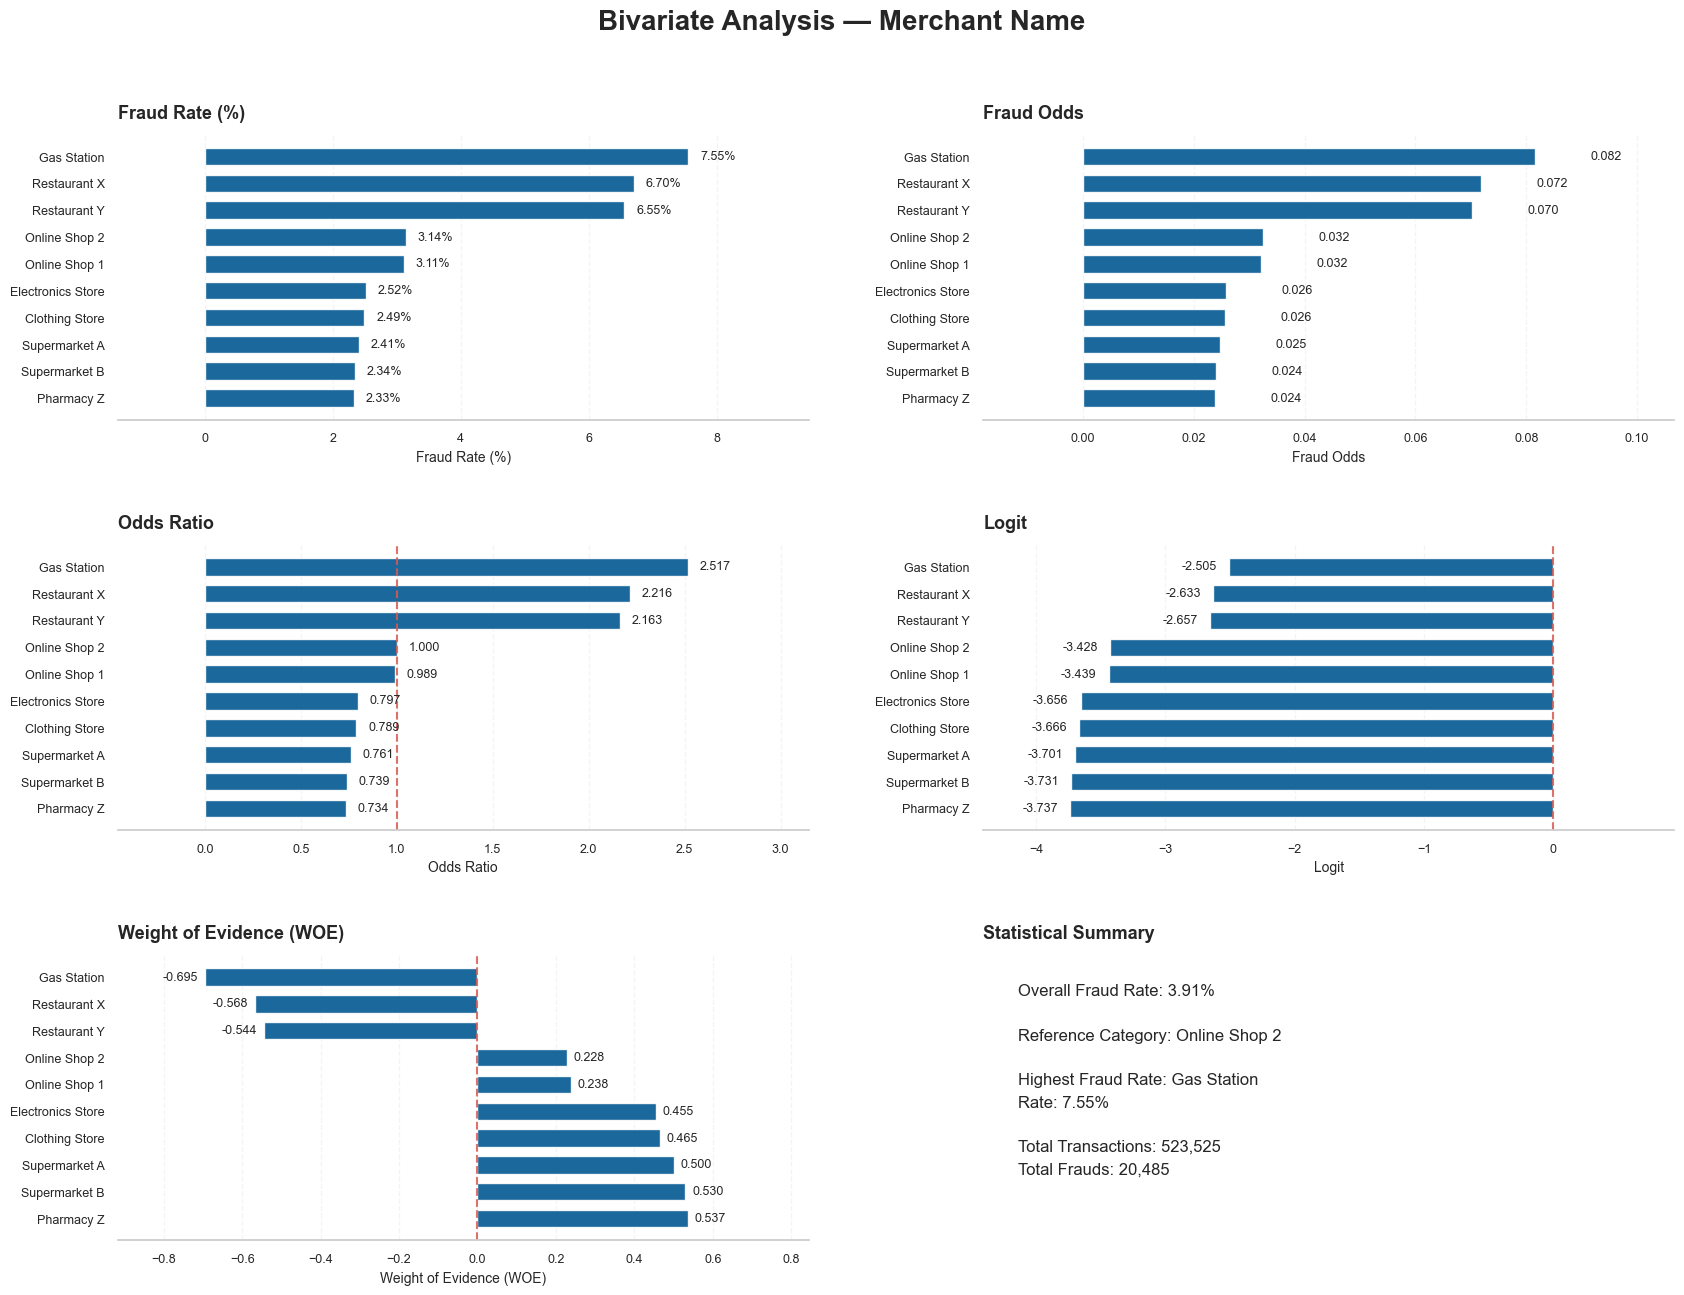

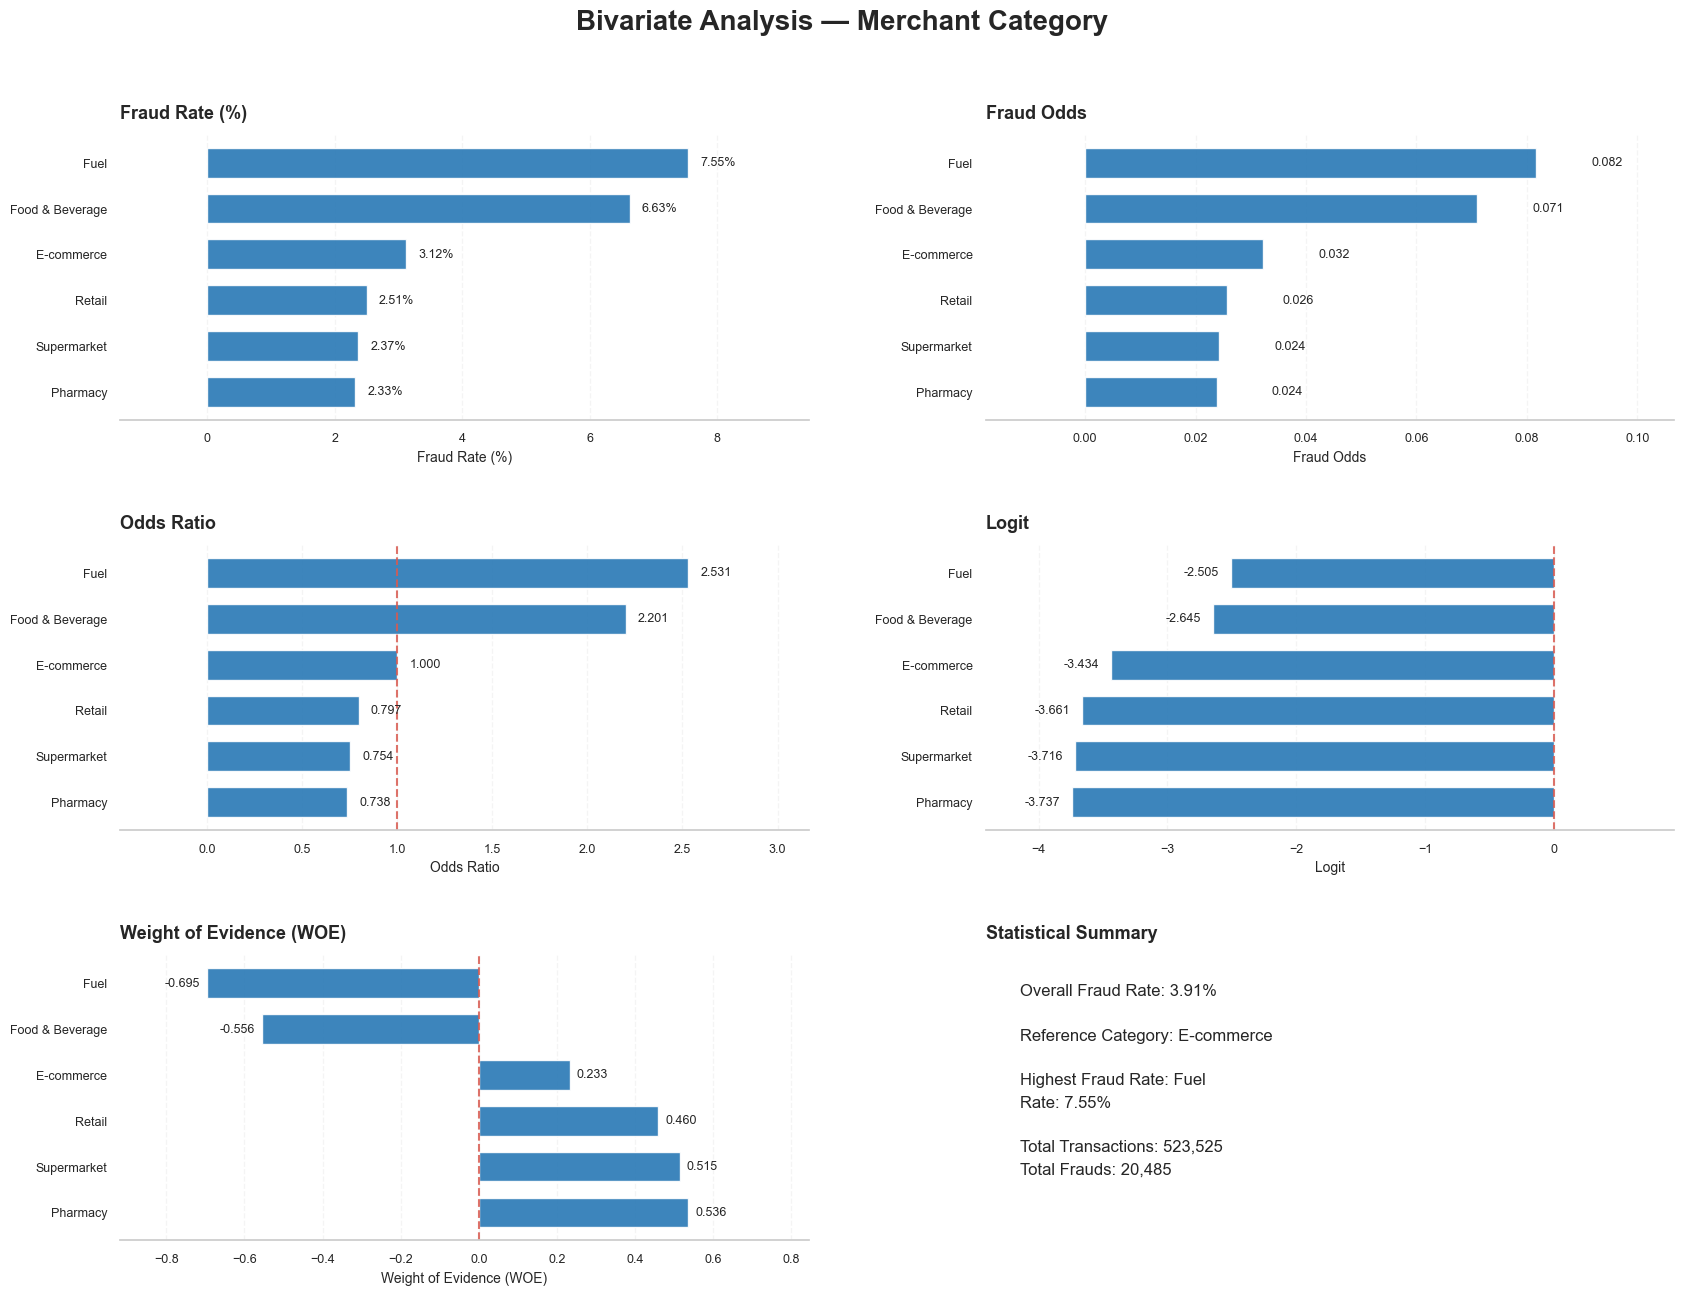

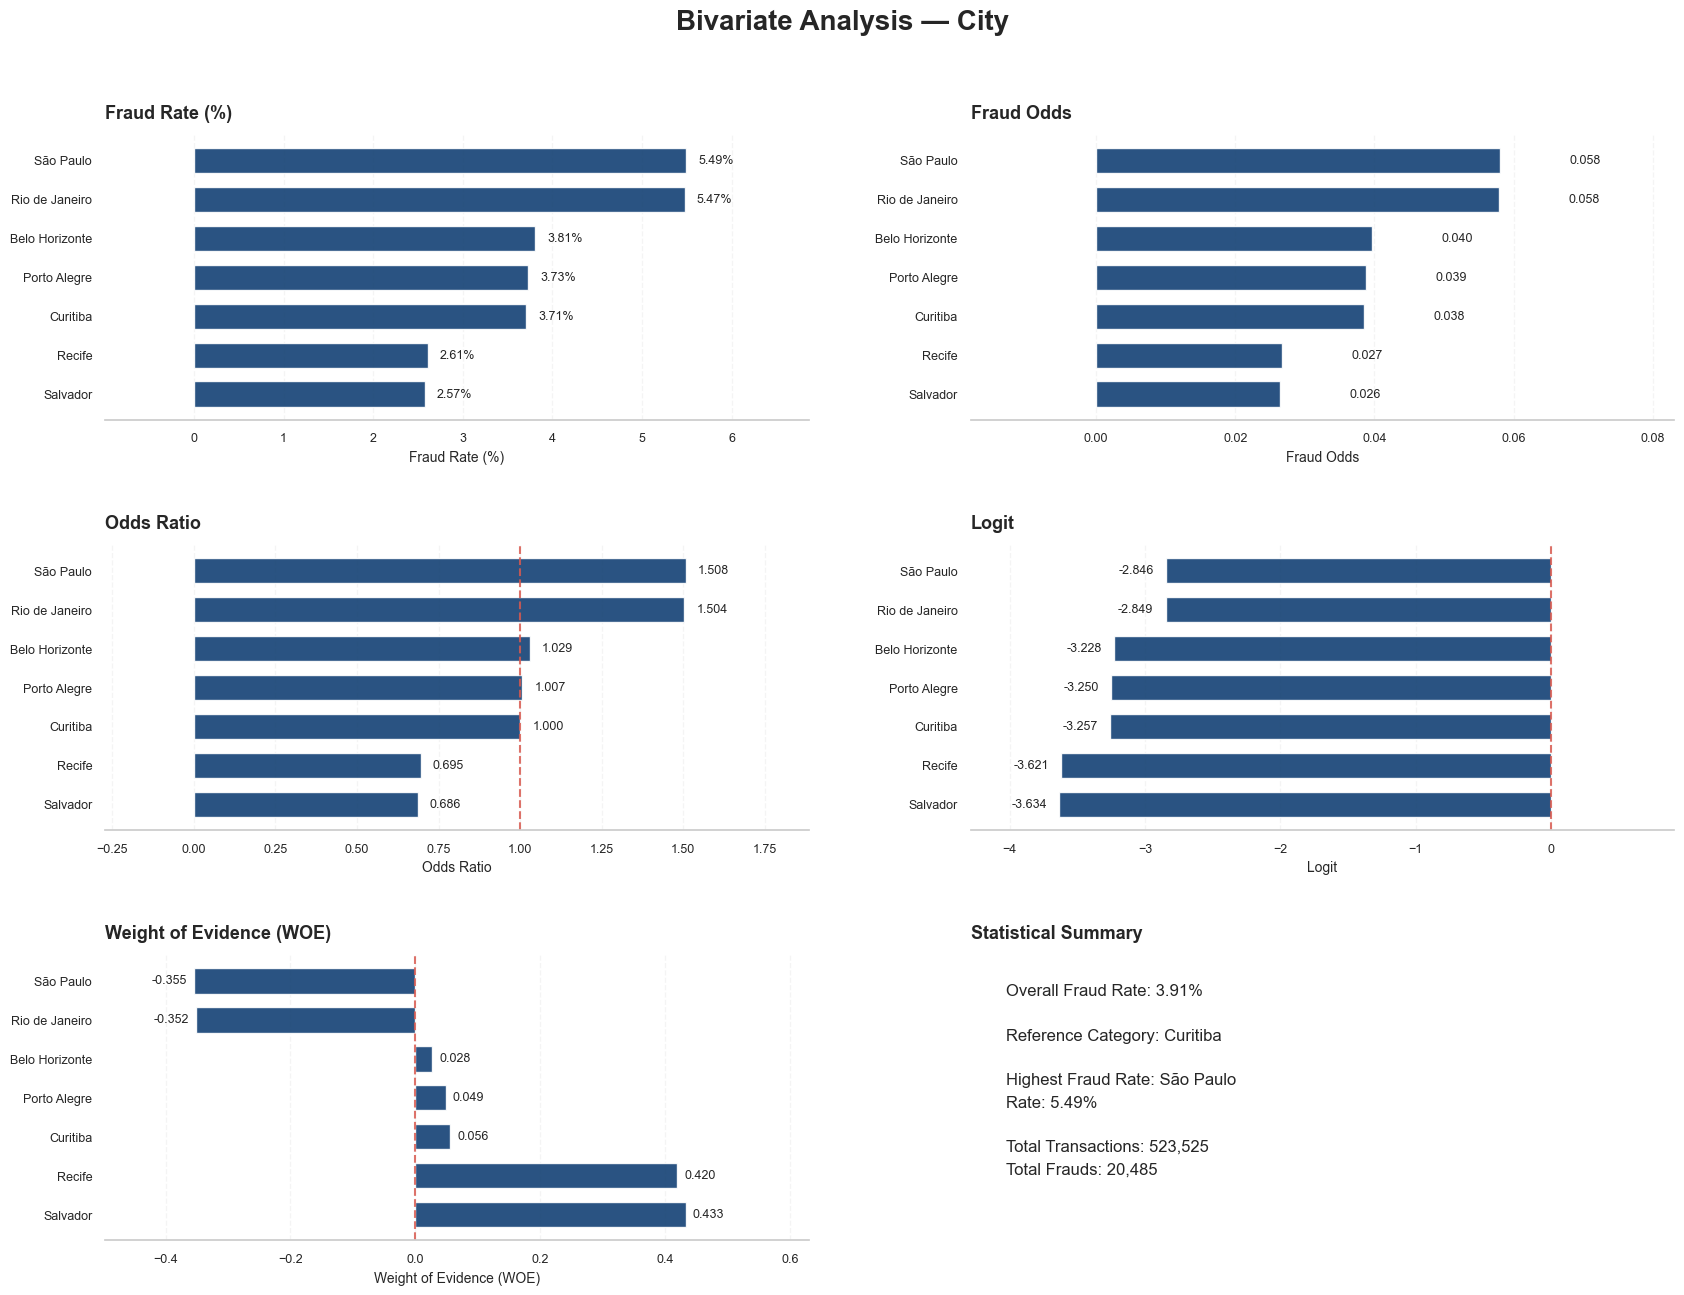

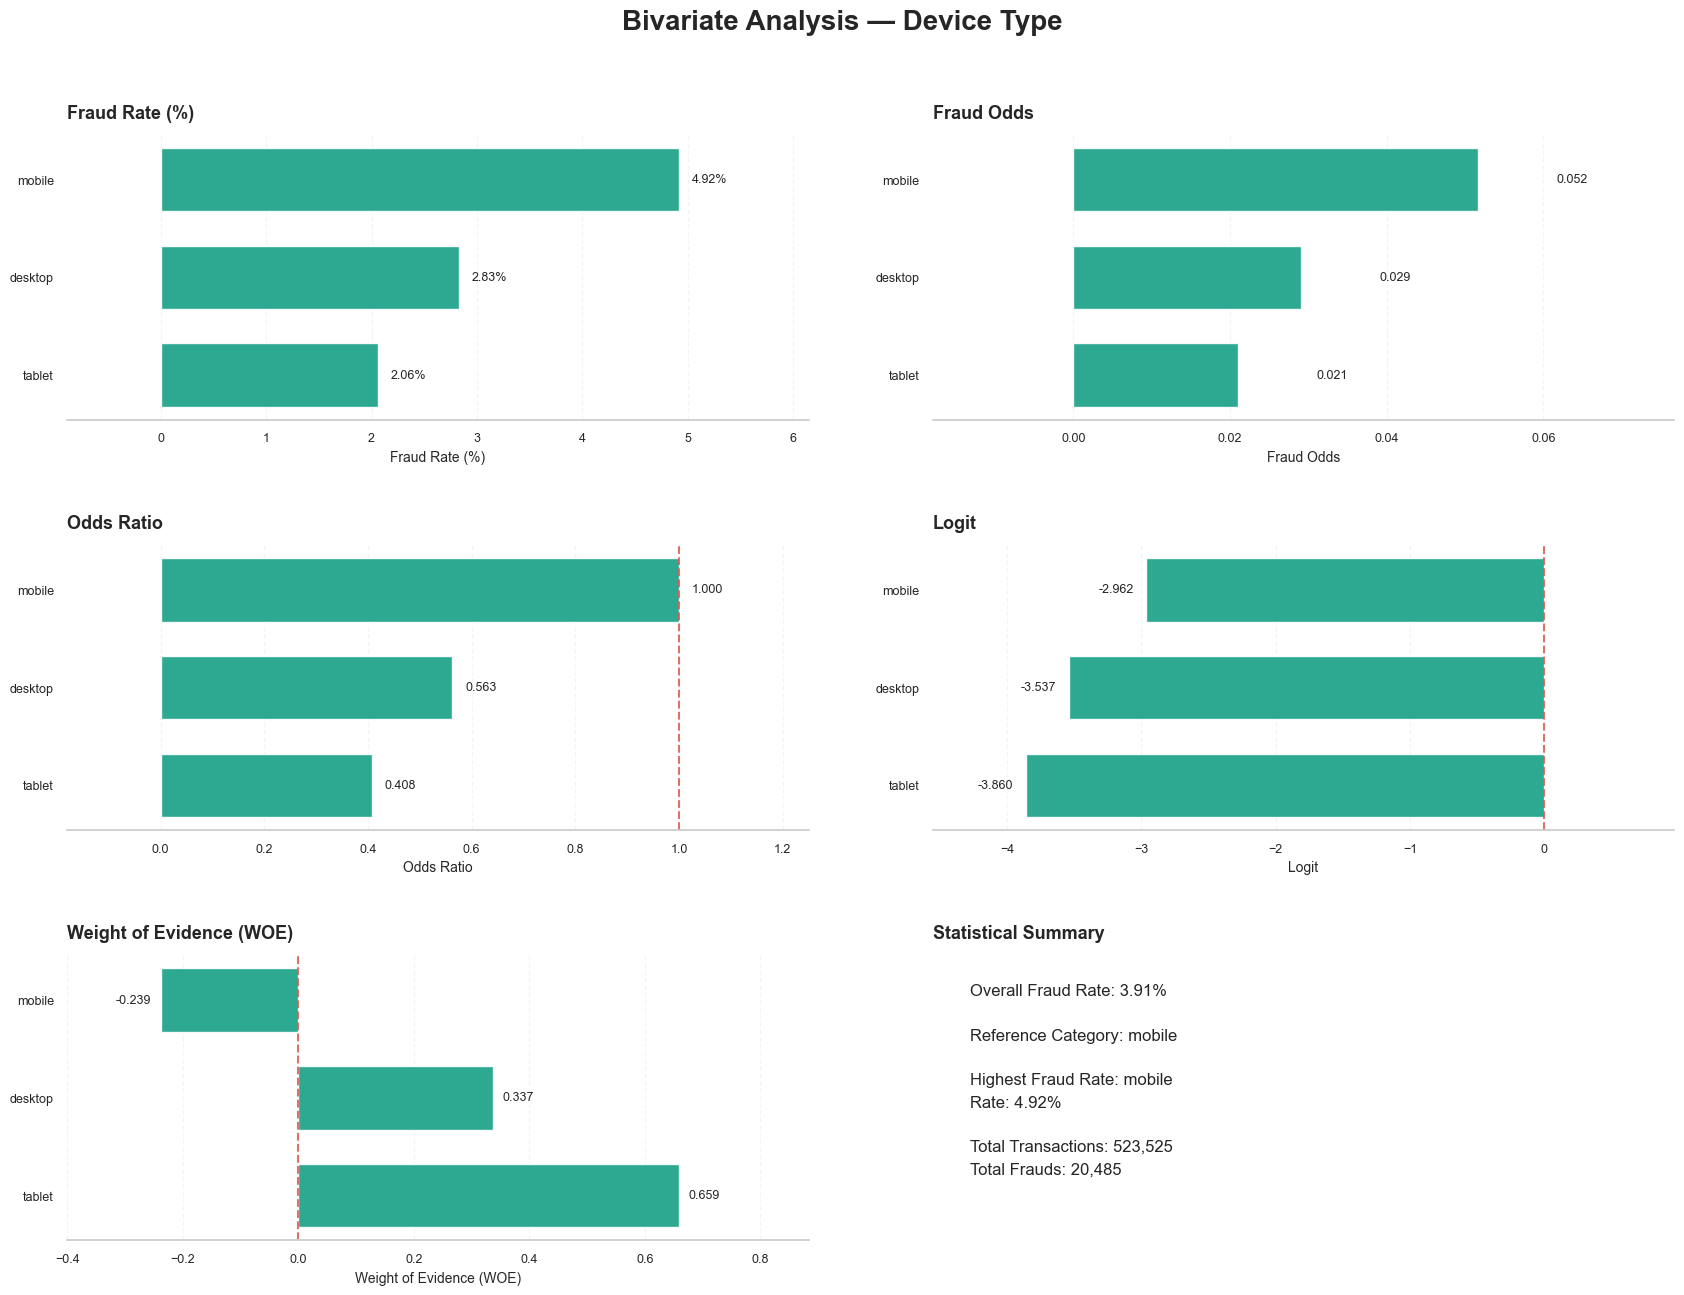

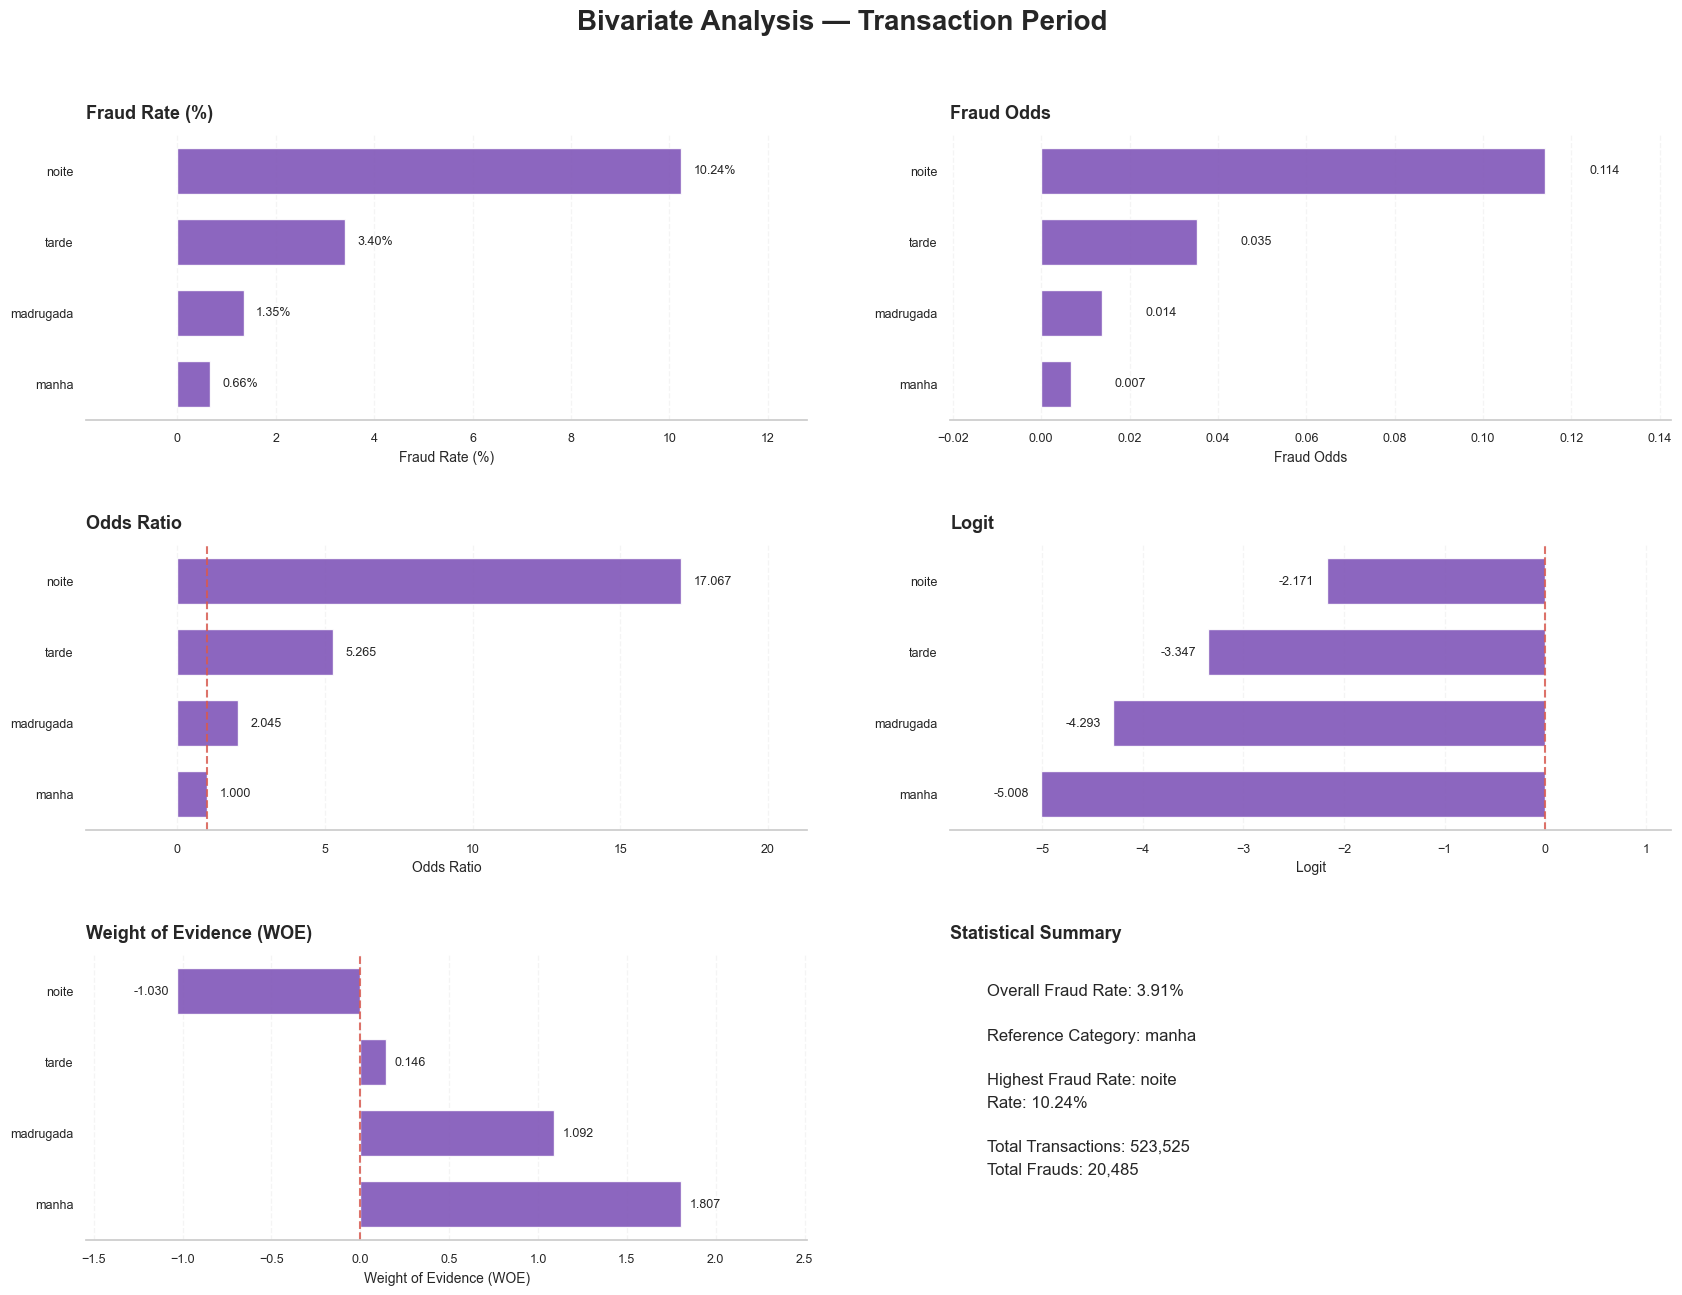

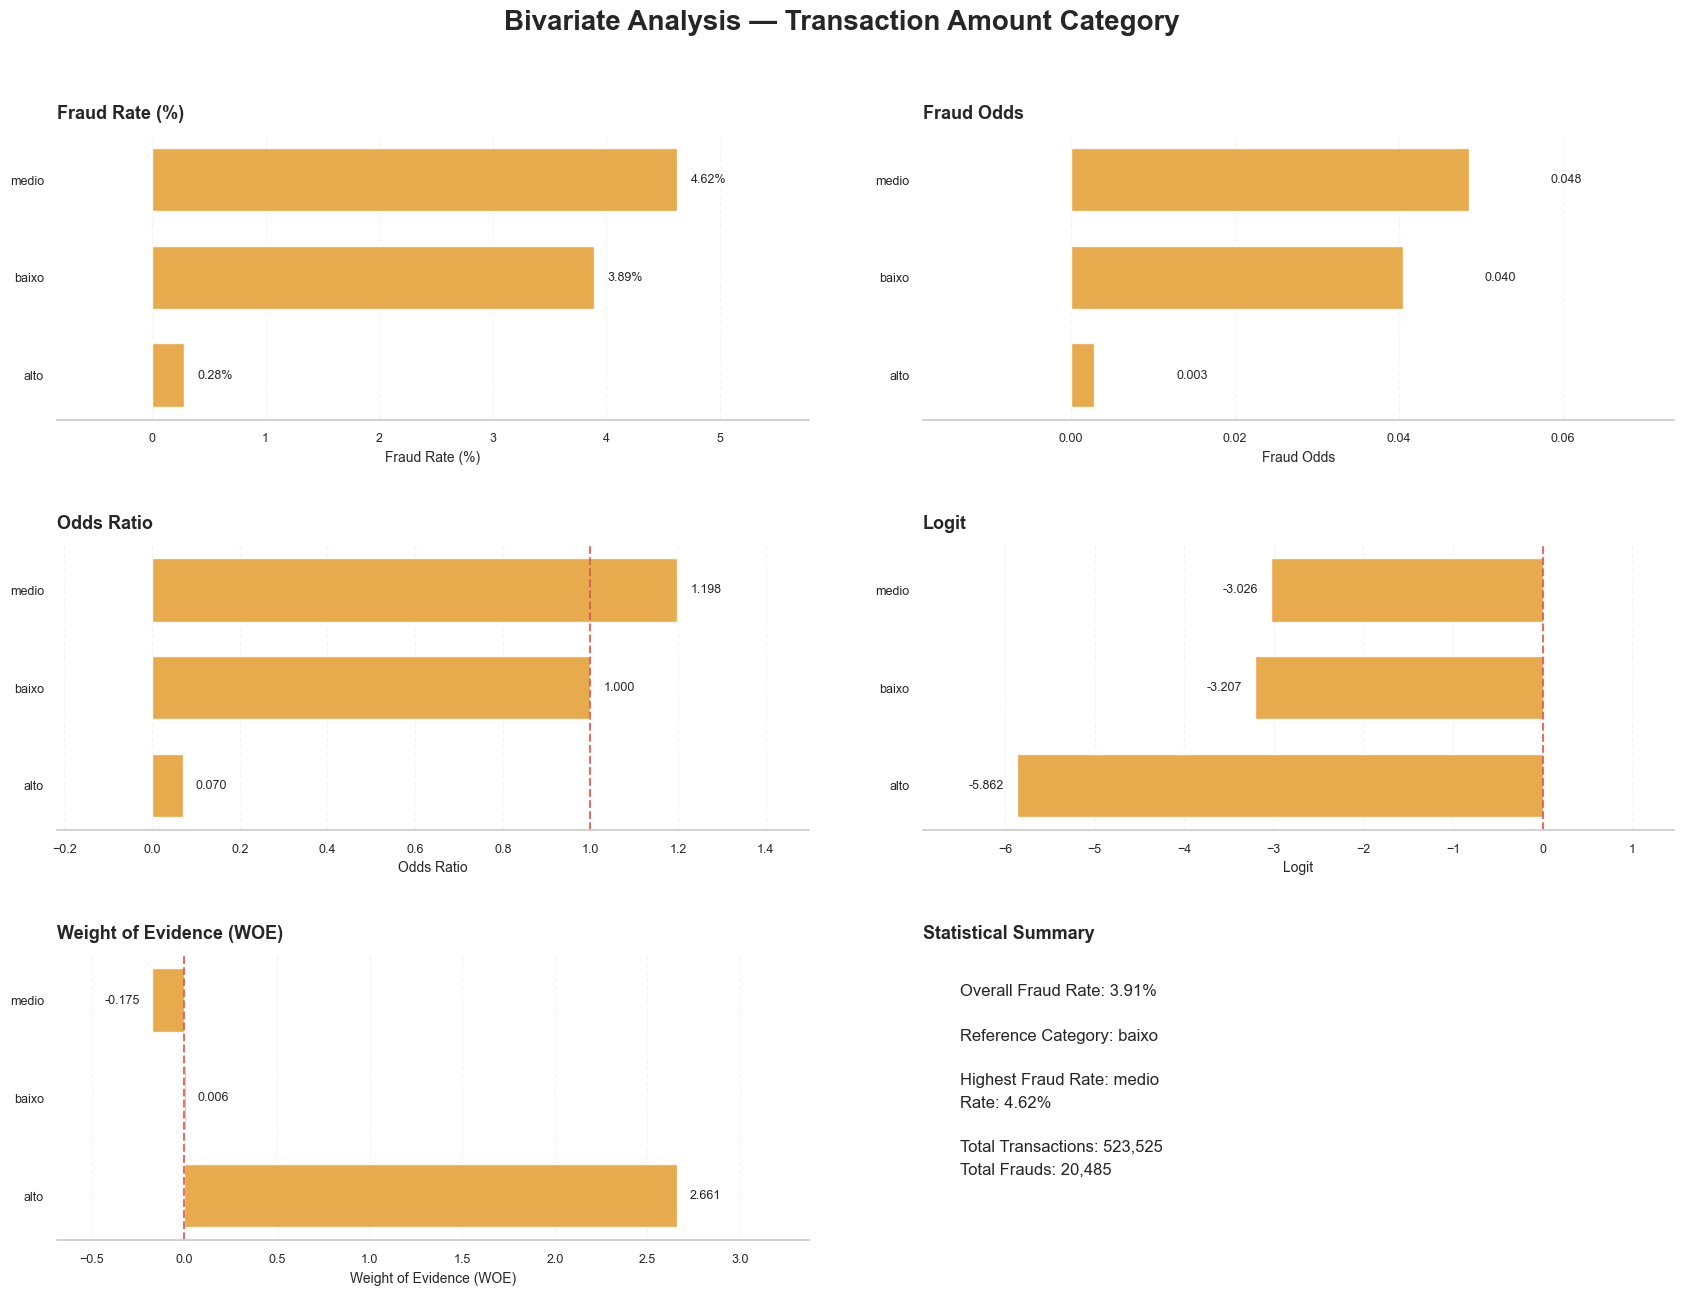

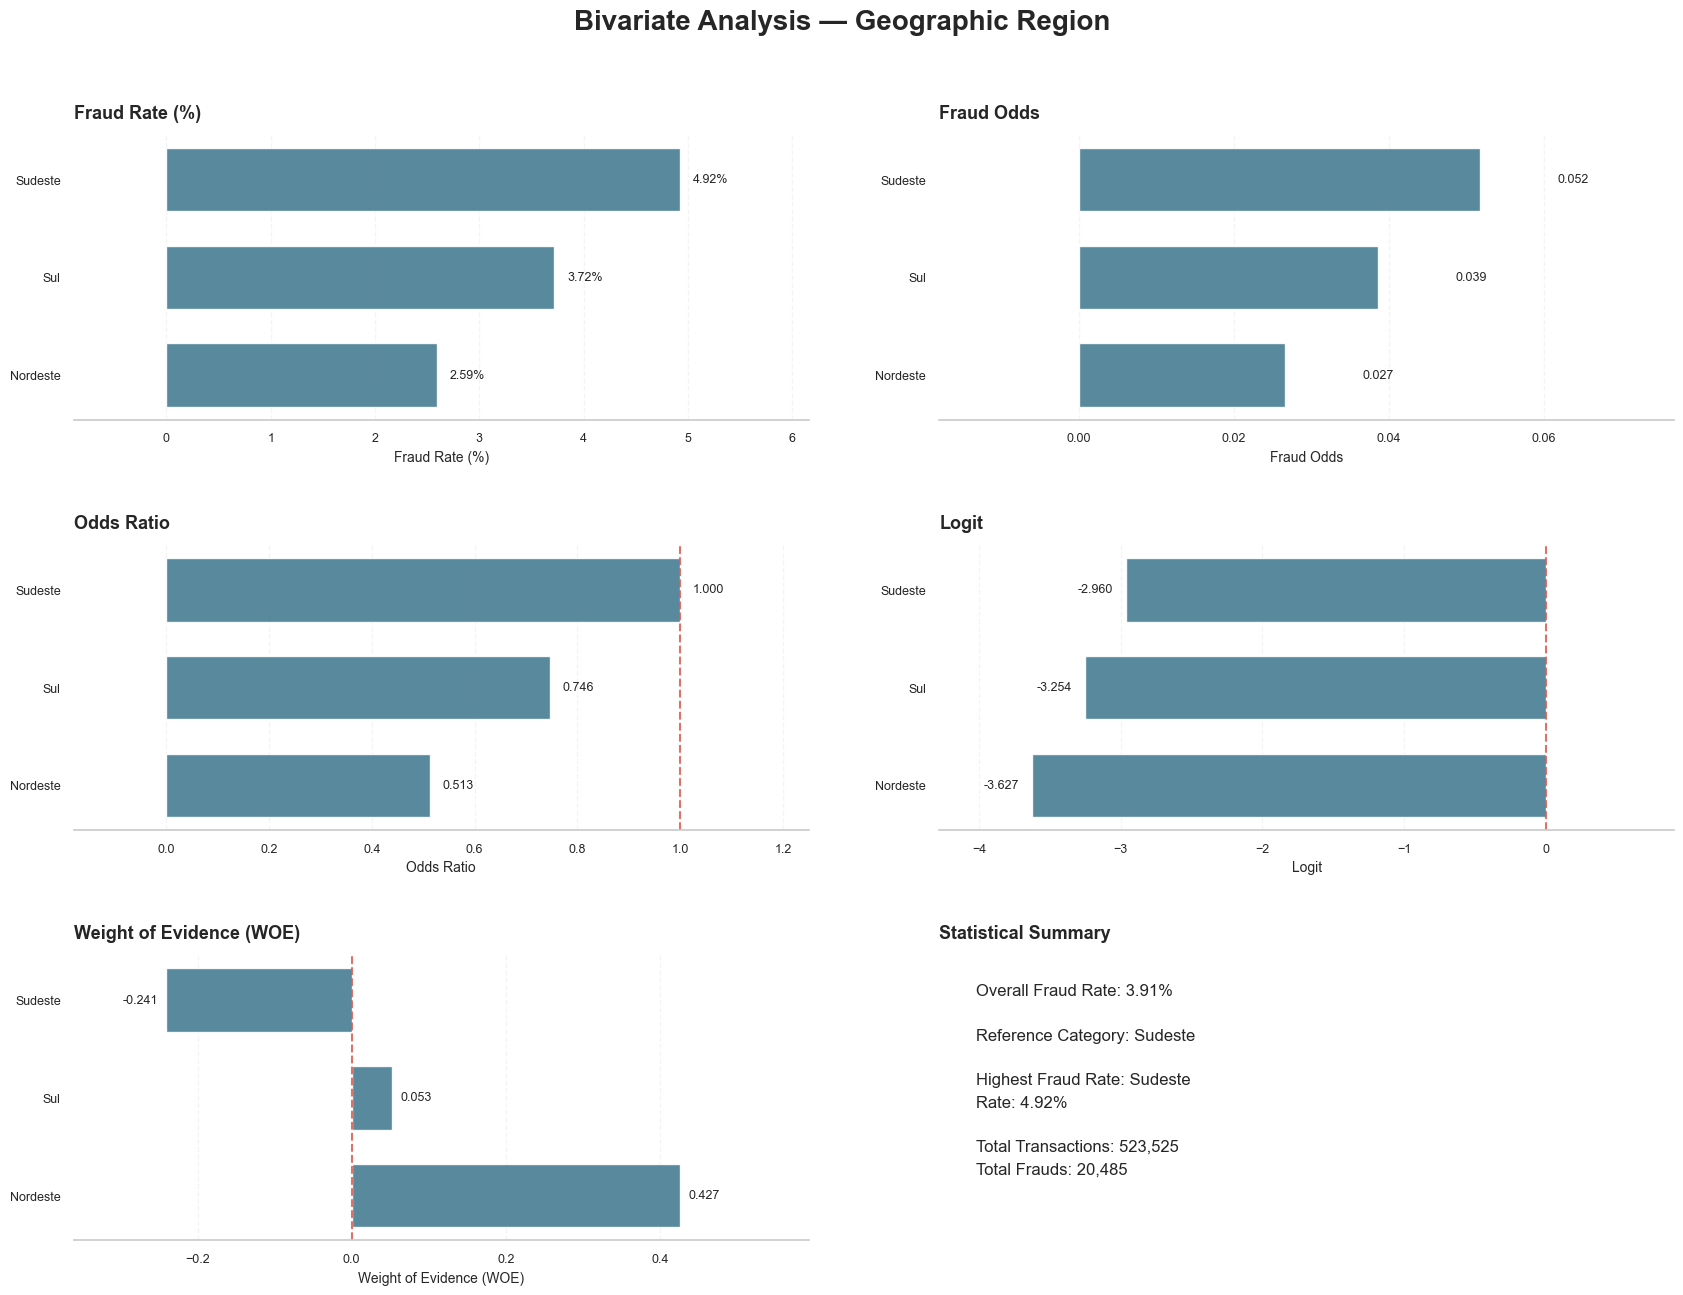

In [44]:
bivariate_results = {}

for feature, color in zip(categorical_features, colors):

    summary = plot_bivariate_dashboard(
        df=df1,
        feature=feature,
        color=color,
        target='flag_fraude'
    )

    bivariate_results[feature] = summary

#### **📊📃Bivariate Analysis: Key Findings**

The analysis of Fraud Rate, Odds Ratio, Logit, and Weight of Evidence (WOE) revealed notable differences in fraud occurrence across categorical features. Nighttime transactions showed the strongest association, with 17.07 times higher odds of fraud compared to morning transactions. Fuel purchases (OR = 2.53) and mobile devices (4.92% fraud rate) also exhibited elevated fraud risk. These findings suggest potential predictive relationships to be further evaluated through statistical testing and Logistic Regression.

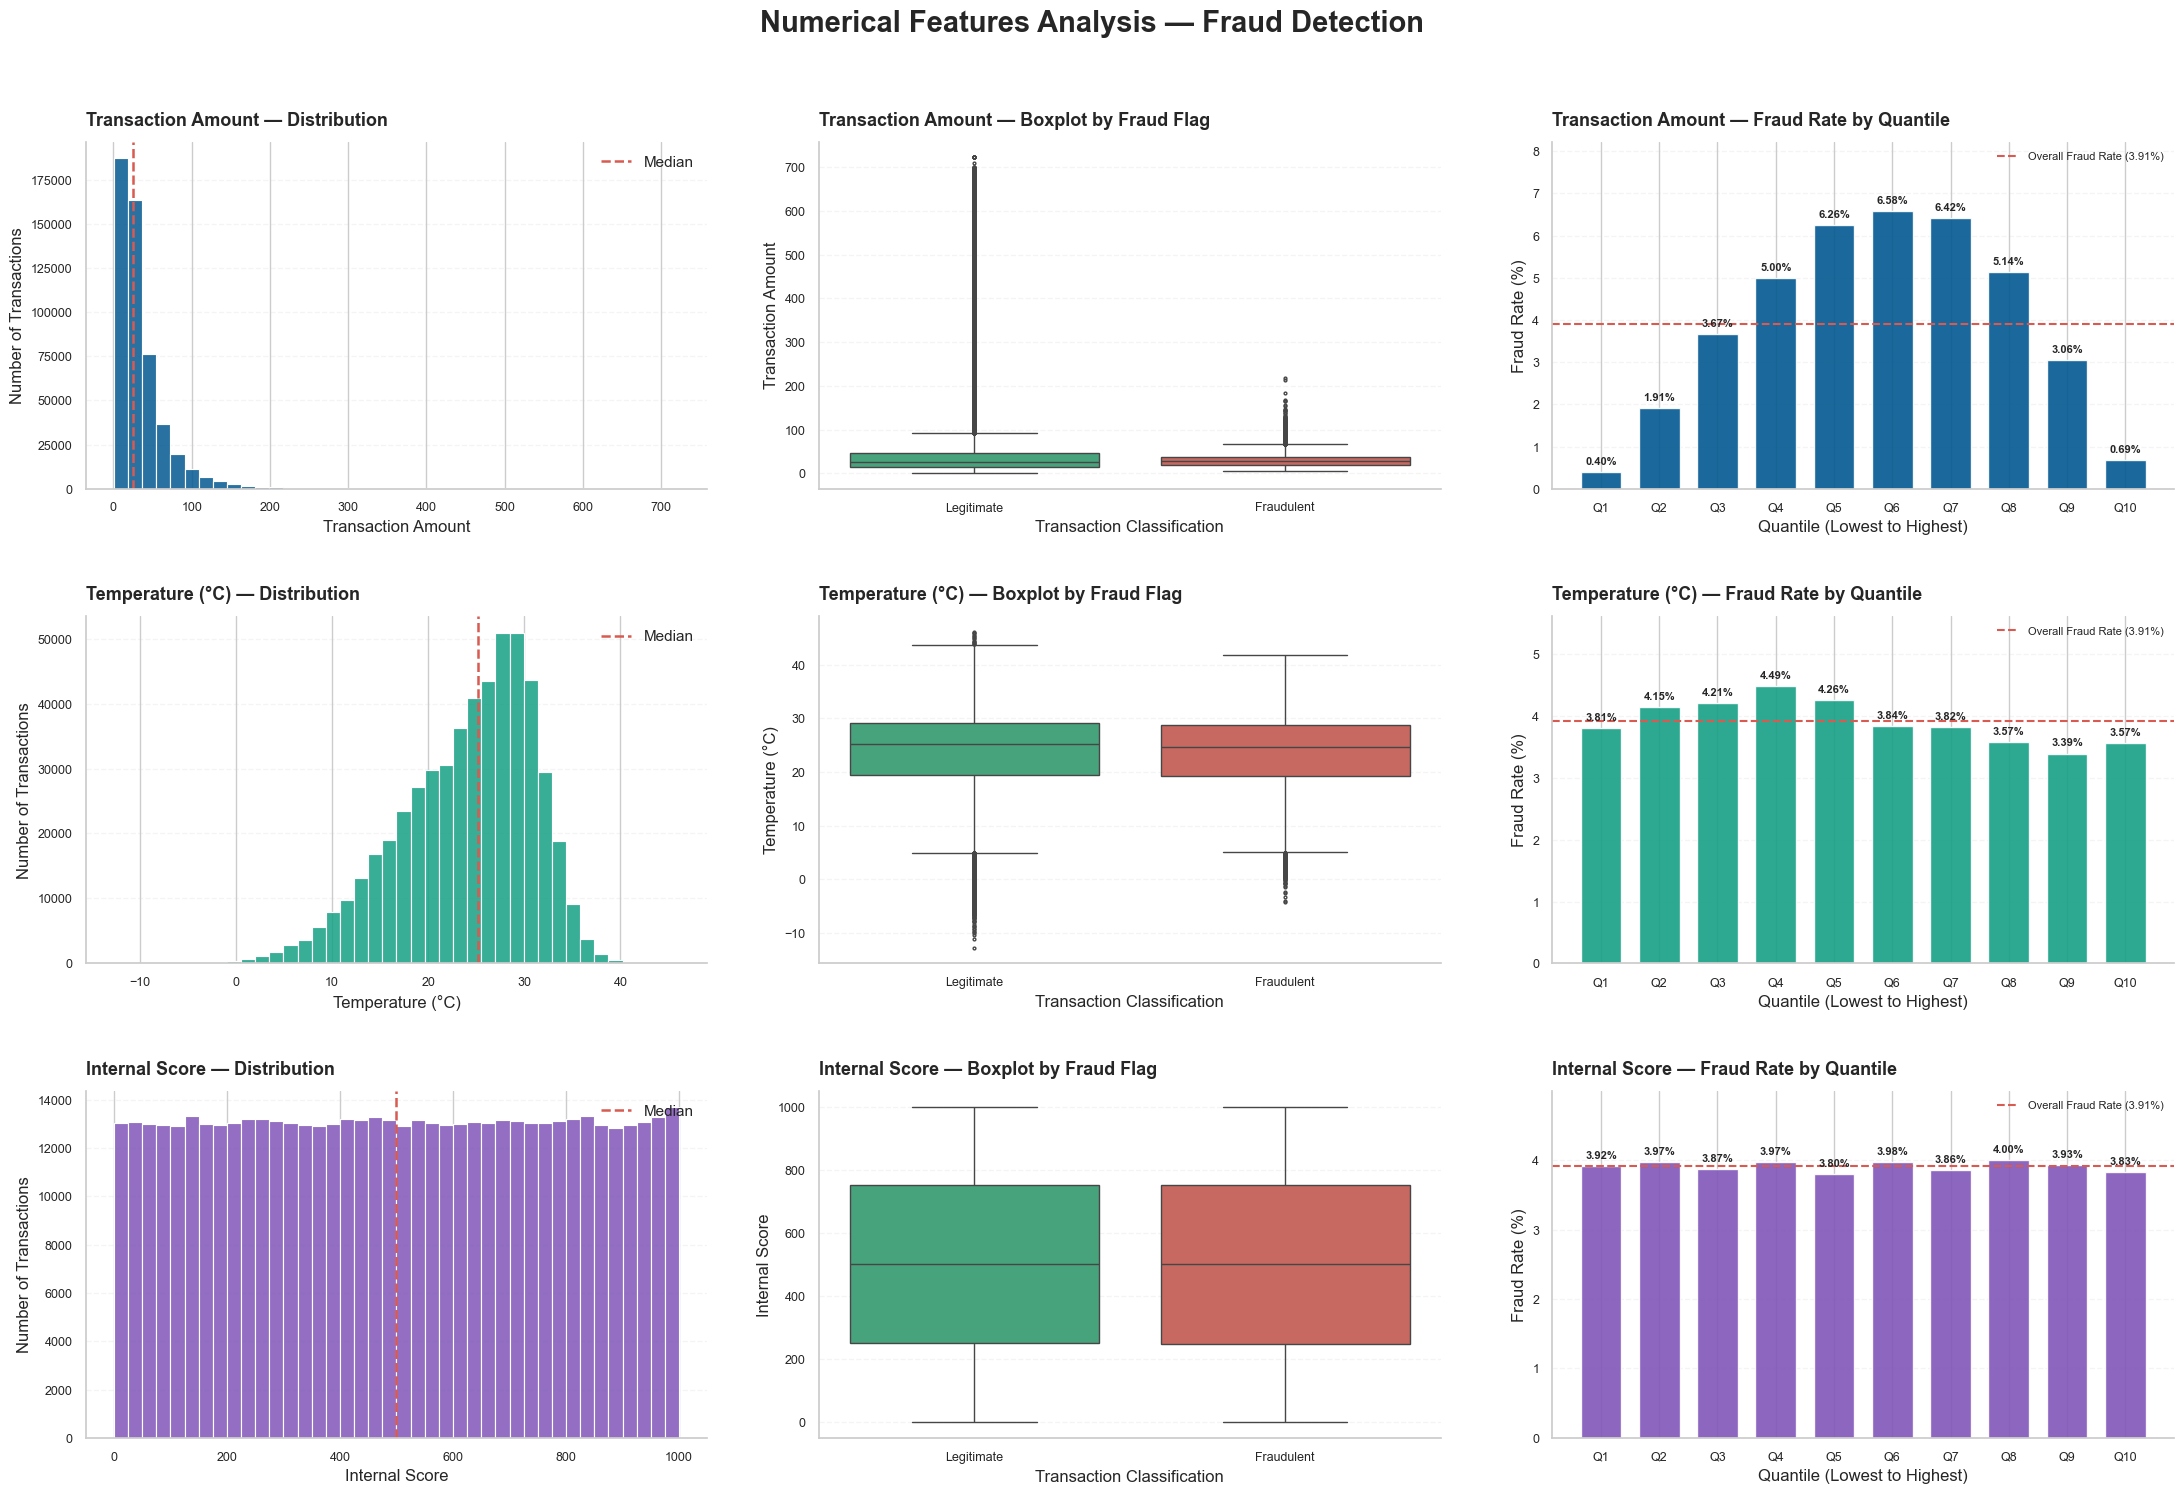

In [45]:
# CONFIGURATION

numerical_features = [
    'valor_transacao',
    'temperatura_celsius',
    'score_interno'
]

feature_titles = {
    'valor_transacao': 'Transaction Amount',
    'temperatura_celsius': 'Temperature (°C)',
    'score_interno': 'Internal Score'
}

colors = {
    'valor_transacao': '#025891',
    'temperatura_celsius': '#16A085',
    'score_interno': '#8055B8'
}

fraud_colors = {
    False: '#36B37E',
    True: '#D85A50'
}

target = 'flag_fraude'

sns.set_theme(style='whitegrid')

# DATA VALIDATION

data = df1[numerical_features + [target]].copy()

for col in numerical_features:
    data[col] = pd.to_numeric(data[col], errors='coerce')

data[target] = data[target].astype('boolean')

if data[target].isna().any():
    raise ValueError('The target contains missing values.')

# DASHBOARD

fig, axes = plt.subplots(
    3, 3,
    figsize=(22, 15)
)

fig.suptitle(
    'Numerical Features Analysis — Fraud Detection',
    fontsize=21,
    fontweight='bold',
    y=0.995
)

for i, col in enumerate(numerical_features):

    color = colors[col]
    title = feature_titles[col]

    subset = data[[col, target]].dropna().copy()

    # 1. DISTRIBUTION

    ax = axes[i, 0]

    sns.histplot(
        data=subset,
        x=col,
        bins=40,
        color=color,
        edgecolor='white',
        alpha=0.85,
        ax=ax
    )

    ax.axvline(
        subset[col].median(),
        color='#D85A50',
        linestyle='--',
        linewidth=1.8,
        label='Median'
    )

    ax.set_title(
        f'{title} — Distribution',
        fontsize=13,
        fontweight='bold',
        loc='left',
        pad=12
    )

    ax.set_xlabel(title)
    ax.set_ylabel('Number of Transactions')
    ax.legend(frameon=False)

    # 2. BOXPLOT BY FRAUD FLAG

    ax = axes[i, 1]

    sns.boxplot(
        data=subset,
        x=target,
        y=col,
        hue=target,
        order=[False, True],
        hue_order=[False, True],
        palette=fraud_colors,
        legend=False,
        showfliers=True,
        fliersize=2,
        ax=ax
    )

    ax.set_title(
        f'{title} — Boxplot by Fraud Flag',
        fontsize=13,
        fontweight='bold',
        loc='left',
        pad=12
    )

    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Legitimate', 'Fraudulent'])

    ax.set_xlabel('Transaction Classification')
    ax.set_ylabel(title)

    # 3. FRAUD RATE BY QUANTILE

    ax = axes[i, 2]

    # Quantile bins; duplicates handles repeated values
    subset['quantile'] = pd.qcut(
        subset[col],
        q=10,
        duplicates='drop'
    )

    summary = (
        subset.groupby(
            'quantile',
            observed=True
        )[target]
        .agg(['mean', 'count'])
        .reset_index()
    )

    summary['fraud_rate'] = (
        summary['mean'].astype(float) * 100
    )

    # Numeric positions for bars
    positions = np.arange(len(summary))

    bars = ax.bar(
        positions,
        summary['fraud_rate'],
        color=color,
        alpha=0.90,
        width=0.70
    )

    # Overall fraud rate
    overall_rate = subset[target].mean() * 100

    ax.axhline(
        overall_rate,
        color='#D85A50',
        linestyle='--',
        linewidth=1.5,
        label=f'Overall Fraud Rate ({overall_rate:.2f}%)'
    )

    # Percentage labels
    for bar, rate in zip(bars, summary['fraud_rate']):

        ax.annotate(
            f'{rate:.2f}%',
            xy=(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height()
            ),
            xytext=(0, 4),
            textcoords='offset points',
            ha='center',
            va='bottom',
            fontsize=8,
            fontweight='bold'
        )

    ax.set_xticks(positions)

    ax.set_xticklabels(
        [f'Q{j+1}' for j in positions],
        rotation=0
    )

    ax.set_ylim(
        0,
        max(
            summary['fraud_rate'].max(),
            overall_rate
        ) * 1.25
    )

    ax.set_title(
        f'{title} — Fraud Rate by Quantile',
        fontsize=13,
        fontweight='bold',
        loc='left',
        pad=12
    )

    ax.set_xlabel('Quantile (Lowest to Highest)')
    ax.set_ylabel('Fraud Rate (%)')
    ax.legend(frameon=False, fontsize=8)

    # VISUAL STYLING

    for chart in axes[i]:

        chart.spines[
            ['top', 'right']
        ].set_visible(False)

        chart.grid(
            axis='y',
            linestyle='--',
            alpha=0.20
        )

        chart.set_axisbelow(True)

        chart.tick_params(
            axis='both',
            labelsize=9
        )

plt.tight_layout(
    rect=[0, 0, 1, 0.97],
    h_pad=3,
    w_pad=3
)

plt.show()


#### **📊📃Numerical Features Analysis: Key Findings**

The analysis revealed a nonlinear relationship between transaction amount and fraud occurrence, with higher fraud rates in intermediate transaction quantiles. Temperature showed relatively small variations in fraud rates, while the internal score exhibited an approximately uniform distribution and limited individual discriminatory power. These findings suggest that transaction amount may require nonlinear transformations during Logistic Regression modeling, while the predictive contribution of the remaining features requires further evaluation.

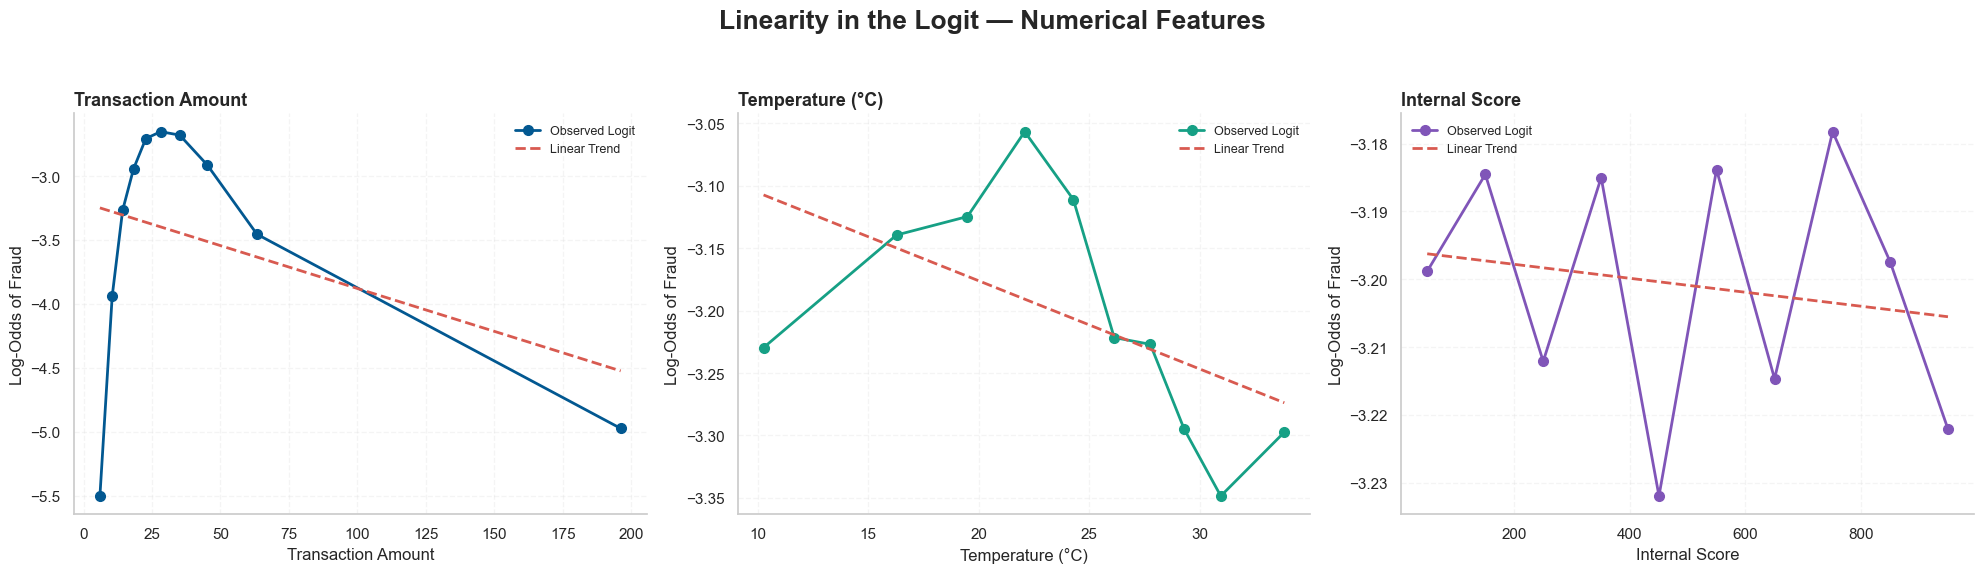

In [46]:
numerical_features = [
    'valor_transacao',
    'temperatura_celsius',
    'score_interno'
]

feature_titles = {
    'valor_transacao': 'Transaction Amount',
    'temperatura_celsius': 'Temperature (°C)',
    'score_interno': 'Internal Score'
}

colors = {
    'valor_transacao': '#025891',
    'temperatura_celsius': '#16A085',
    'score_interno': '#8055B8'
}

target = 'flag_fraude'

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))

for ax, feature in zip(axes, numerical_features):

    data = df1[[feature, target]].dropna().copy()

    data[feature] = pd.to_numeric(data[feature])
    data[target] = data[target].astype(int)

    # Create quantile bins
    data['bin'] = pd.qcut(
        data[feature],
        q=10,
        duplicates='drop'
    )

    # Calculate fraud counts and mean feature values
    summary = (
        data.groupby('bin', observed=True)
        .agg(
            mean_value=(feature, 'mean'),
            fraud_count=(target, 'sum'),
            total=(target, 'size')
        )
        .reset_index()
    )

    summary['legitimate_count'] = (
        summary['total'] - summary['fraud_count']
    )

    # Smoothed odds and logit
    summary['logit'] = np.log(
        (summary['fraud_count'] + 0.5) /
        (summary['legitimate_count'] + 0.5)
    )

    x = summary['mean_value'].to_numpy(dtype=float)
    y = summary['logit'].to_numpy(dtype=float)
    weights = summary['total'].to_numpy(dtype=float)

    # Weighted linear trend
    coefficients = np.polyfit(
        x, y, deg=1, w=np.sqrt(weights)
    )

    x_line = np.linspace(x.min(), x.max(), 200)
    y_line = np.polyval(coefficients, x_line)

    # Observed logit
    ax.plot(
        x, y,
        marker='o',
        markersize=7,
        linewidth=2,
        color=colors[feature],
        label='Observed Logit'
    )

    # Linear approximation
    ax.plot(
        x_line, y_line,
        linestyle='--',
        linewidth=2,
        color='#D85A50',
        label='Linear Trend'
    )

    ax.set_title(
        feature_titles[feature],
        fontsize=13,
        fontweight='bold',
        loc='left'
    )

    ax.set_xlabel(feature_titles[feature])
    ax.set_ylabel('Log-Odds of Fraud')

    ax.grid(
        linestyle='--',
        alpha=0.20
    )

    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(frameon=False, fontsize=9)

fig.suptitle(
    'Linearity in the Logit — Numerical Features',
    fontsize=19,
    fontweight='bold',
    y=1.04
)

plt.tight_layout()
plt.show()


#### **📊📃Linearity in the Logit: Key Findings**

The analysis revealed a pronounced nonlinear relationship between transaction amount and fraud log-odds, with higher fraud likelihood at intermediate transaction values. Temperature exhibited a weaker nonlinear pattern, while internal score showed minimal variation and no clear trend. These findings suggest evaluating polynomial terms or splines for transaction amount during Logistic Regression modeling, while assessing the incremental predictive contribution of the remaining features.

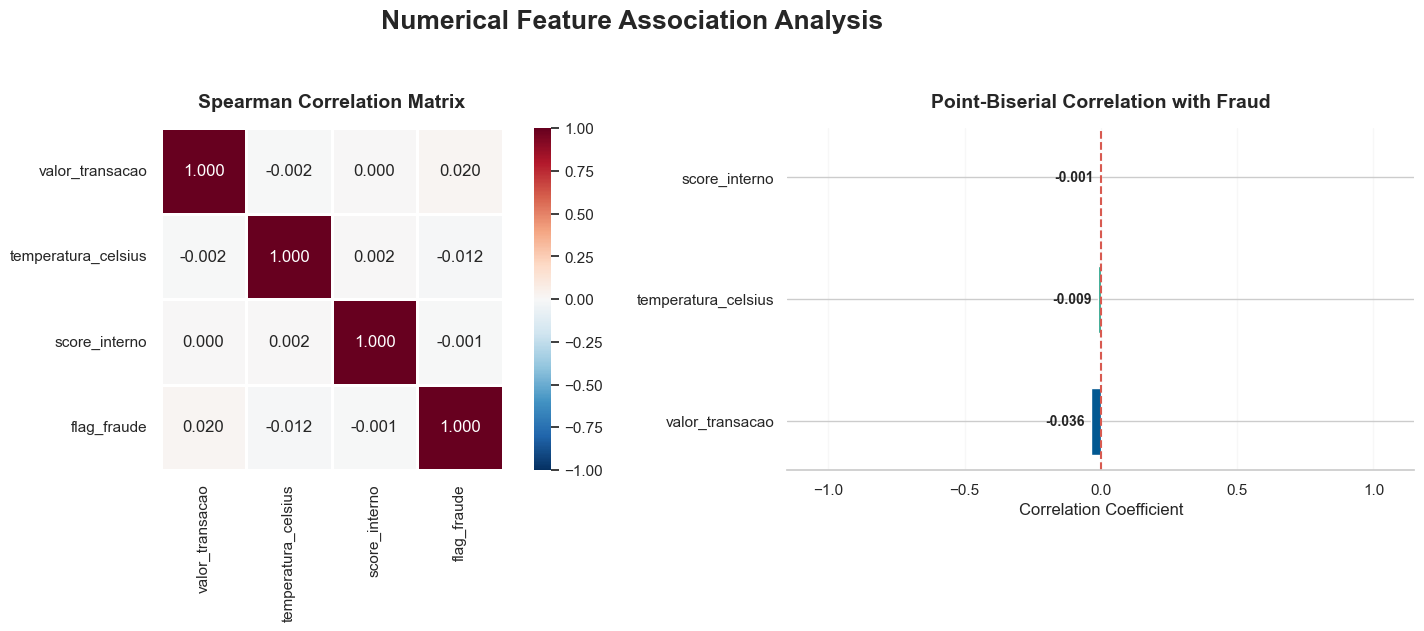

,Feature,Correlation,P-value
0,valor_transacao,-0.0355,0.0000
1,temperatura_celsius,-0.0089,0.0000
2,score_interno,-0.0007,0.6008


In [47]:
features = [
    'valor_transacao',
    'temperatura_celsius',
    'score_interno'
]

target = 'flag_fraude'

data = df1[features + [target]].copy()

data[target] = data[target].astype(int)

# 1. SPEARMAN CORRELATION

spearman_corr = data.corr(method='spearman')

# 2. POINT-BISERIAL CORRELATION

results = []

for feature in features:

    subset = data[[feature, target]].dropna()

    r, p_value = pointbiserialr(
        subset[target],
        subset[feature]
    )

    results.append({
        'Feature': feature,
        'Correlation': r,
        'P-value': p_value
    })

point_biserial = pd.DataFrame(results)

# DASHBOARD

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 6)
)

# Spearman Heatmap
sns.heatmap(
    spearman_corr,
    annot=True,
    fmt='.3f',
    cmap='RdBu_r',
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.8,
    ax=axes[0]
)

axes[0].set_title(
    'Spearman Correlation Matrix',
    fontsize=14,
    fontweight='bold',
    pad=15
)

# Point-Biserial Correlation
bars = axes[1].barh(
    point_biserial['Feature'],
    point_biserial['Correlation'],
    color=['#025891', '#16A085', '#8055B8'],
    height=0.55
)

axes[1].axvline(
    0,
    color='#D85A50',
    linestyle='--'
)

for bar, value in zip(
    bars,
    point_biserial['Correlation']
):

    axes[1].annotate(
        f'{value:.3f}',
        xy=(
            value,
            bar.get_y() + bar.get_height() / 2
        ),
        xytext=(5 if value >= 0 else -5, 0),
        textcoords='offset points',
        ha='left' if value >= 0 else 'right',
        va='center',
        fontsize=10,
        fontweight='bold'
    )

axes[1].set_xlim(-1.15, 1.15)

axes[1].set_title(
    'Point-Biserial Correlation with Fraud',
    fontsize=14,
    fontweight='bold',
    pad=15
)

axes[1].set_xlabel('Correlation Coefficient')
axes[1].set_ylabel('')

axes[1].grid(axis='x', alpha=0.15)

axes[1].spines[
    ['top', 'right', 'left']
].set_visible(False)

fig.suptitle(
    'Numerical Feature Association Analysis',
    fontsize=19,
    fontweight='bold',
    y=1.04
)

plt.tight_layout()
plt.show()

# Statistical results
display(point_biserial.round(4))


#### **📊📃Numerical Feature Association: Key Findings**

The correlation analysis revealed negligible monotonic associations among numerical predictors, with no indication of strong pairwise correlations. Point-biserial correlations with fraud were also close to zero, particularly for temperature and internal score. However, previous analyses identified a pronounced nonlinear relationship between transaction amount and fraud occurrence, highlighting the importance of evaluating nonlinear transformations during Logistic Regression modeling rather than relying solely on correlation coefficients.

### **Data Preparation**

### **Train / Test Split**

In [48]:
# FEATURE CONFIGURATION

categorical_features = [
    'nome_estabelecimento',
    'tipo_estabelecimento',
    'cidade',
    'device_type',
    'turno',
    'valor_categoria',
    'cidade_regiao'
]

numerical_features = [
    'valor_transacao',
    'temperatura_celsius',
    'score_interno'
]

target = 'flag_fraude'

selected_features = (
    categorical_features + numerical_features
)

# Verify that all required columns exist
required_columns = selected_features + [target]

missing_columns = [
    col for col in required_columns
    if col not in df1.columns
]

if missing_columns:
    raise ValueError(
        f'Missing columns: {missing_columns}'
    )

X = df1[selected_features].copy()
y = df1[target].astype(int).copy()

if not y.isin([0, 1]).all():
    raise ValueError('Target must contain only 0 and 1.')

# STRATIFIED SPLIT

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print('Training samples:', len(X_train))
print('Test samples:', len(X_test))

print(
    'Training fraud rate:',
    f'{y_train.mean():.2%}'
)

print(
    'Test fraud rate:',
    f'{y_test.mean():.2%}'
)


Training samples: 418820
Test samples: 104705
Training fraud rate: 3.91%
Test fraud rate: 3.91%


### **Preprocessing Pipeline: One-Hot Encoding & StandardScaler**

In [49]:
# CATEGORICAL PREPROCESSING

categorical_pipeline = Pipeline(
    steps=[
        (
            'imputer',
            SimpleImputer(
                strategy='most_frequent'
            )
        ),
        (
            'encoder',
            OneHotEncoder(
                handle_unknown='ignore',
                drop='first'
            )
        )
    ]
)

# NUMERICAL PREPROCESSING

numerical_pipeline = Pipeline(
    steps=[
        (
            'imputer',
            SimpleImputer(
                strategy='median'
            )
        ),
        (
            'scaler',
            StandardScaler()
        )
    ]
)

# COLUMN TRANSFORMER

preprocessor = ColumnTransformer(
    transformers=[
        (
            'categorical',
            categorical_pipeline,
            categorical_features
        ),
        (
            'numerical',
            numerical_pipeline,
            numerical_features
        )
    ]
)

print('Preprocessing pipeline configured.')


Preprocessing pipeline configured.


### **Nonlinear Feature Engineering: Transaction Amount**

In [50]:
# Other numerical features
other_numerical_features = [
    'temperatura_celsius',
    'score_interno'
]

# Polynomial transformation
polynomial_pipeline = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('polynomial', PolynomialFeatures(
            degree=2,
            include_bias=False
        ))
    ]
)

# Spline transformation
spline_pipeline = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('spline', SplineTransformer(
            n_knots=5,
            degree=3,
            include_bias=False
        )),
        ('scaler', StandardScaler())
    ]
)

def build_preprocessor(amount_transform='linear'):

    if amount_transform == 'polynomial':
        amount_pipeline = polynomial_pipeline

    elif amount_transform == 'spline':
        amount_pipeline = spline_pipeline

    elif amount_transform == 'linear':
        amount_pipeline = numerical_pipeline

    else:
        raise ValueError('Unknown transformation.')

    return ColumnTransformer(
        transformers=[
            (
                'categorical',
                categorical_pipeline,
                categorical_features
            ),
            (
                'amount',
                amount_pipeline,
                ['valor_transacao']
            ),
            (
                'other_numerical',
                numerical_pipeline,
                other_numerical_features
            )
        ]
    )


### **Modeling**

In [51]:
# CROSS-VALIDATION

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

transformations = [
    'linear',
    'polynomial',
    'spline'
]

class_weights = [
    None,
    'balanced'
]

# MODEL COMPARISON

for transformation in transformations:

    for weight in class_weights:

        model = Pipeline(
            steps=[
                (
                    'preprocessing',
                    build_preprocessor(transformation)
                ),
                (
                    'classifier',
                    LogisticRegression(
                        class_weight=weight,
                        max_iter=2000,
                        solver='lbfgs',
                        random_state=42
                    )
                )
            ]
        )

        scores = cross_validate(
            model,
            X_train,
            y_train,
            cv=cv,
            scoring={
                'average_precision': 'average_precision',
                'roc_auc': 'roc_auc'
            },
            n_jobs=-1
        )

        results.append({
            'Transformation': transformation,
            'Class Weight': str(weight),
            'AP Mean': scores[
                'test_average_precision'
            ].mean(),
            'AP Std': scores[
                'test_average_precision'
            ].std(),
            'ROC-AUC Mean': scores[
                'test_roc_auc'
            ].mean()
        })

comparison = (
    pd.DataFrame(results)
    .sort_values(
        'AP Mean',
        ascending=False
    )
    .reset_index(drop=True)
)

display(comparison.round(4))


,Transformation,Class Weight,AP Mean,AP Std,ROC-AUC Mean
0,spline,None,0.1468,0.0011,0.8649
1,polynomial,None,0.1442,0.0011,0.8632
2,spline,balanced,0.1367,0.0013,0.8685
3,polynomial,balanced,0.1329,0.0011,0.8655
4,linear,None,0.1219,0.0018,0.8450
5,linear,balanced,0.1176,0.0017,0.8497


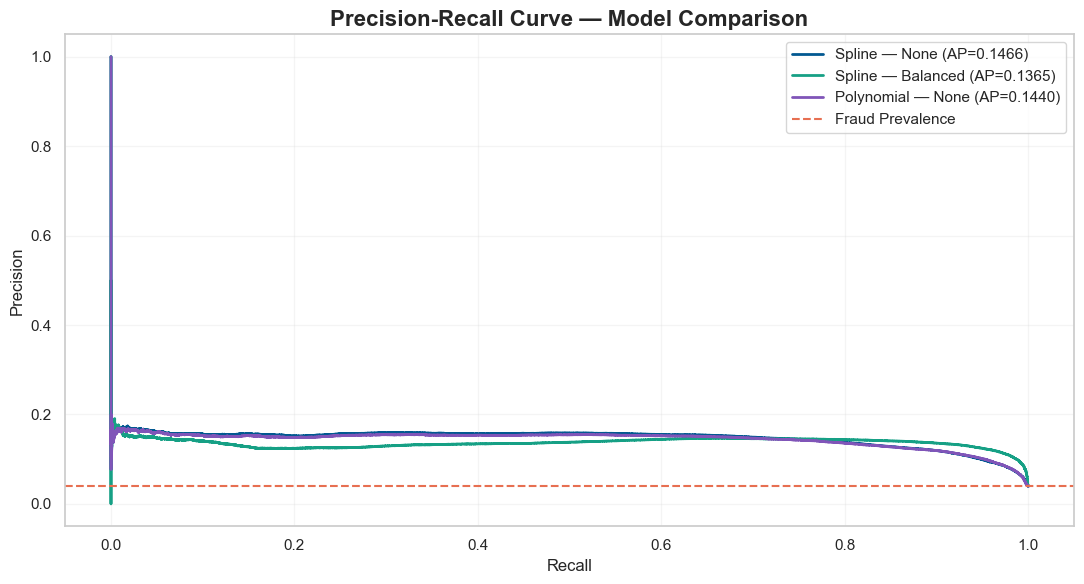

In [52]:
models = {
    'Spline — None': Pipeline([
        ('preprocessing', build_preprocessor('spline')),
        ('classifier', LogisticRegression(
            class_weight=None,
            max_iter=2000,
            random_state=42
        ))
    ]),
    'Spline — Balanced': Pipeline([
        ('preprocessing', build_preprocessor('spline')),
        ('classifier', LogisticRegression(
            class_weight='balanced',
            max_iter=2000,
            random_state=42
        ))
    ]),
    'Polynomial — None': Pipeline([
        ('preprocessing', build_preprocessor('polynomial')),
        ('classifier', LogisticRegression(
            class_weight=None,
            max_iter=2000,
            random_state=42
        ))
    ])
}

colors = ['#025891', '#16A085', '#8055B8']

fig, ax = plt.subplots(figsize=(11, 6))

for (name, model), color in zip(models.items(), colors):

    probabilities = cross_val_predict(
        model,
        X_train,
        y_train,
        cv=cv,
        method='predict_proba',
        n_jobs=-1
    )[:, 1]

    precision, recall, thresholds = precision_recall_curve(
        y_train,
        probabilities
    )

    ap = average_precision_score(
        y_train,
        probabilities
    )

    ax.plot(
        recall,
        precision,
        color=color,
        linewidth=2,
        label=f'{name} (AP={ap:.4f})'
    )

ax.axhline(
    y=y_train.mean(),
    color='#E76F51',
    linestyle='--',
    linewidth=1.5,
    label='Fraud Prevalence'
)

ax.set_title(
    'Precision-Recall Curve — Model Comparison',
    fontsize=16,
    fontweight='bold'
)

ax.set_xlabel('Recall')
ax.set_ylabel('Precision')

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


#### **📊📃Precision-Recall Analysis: Key Findings**

The Precision-Recall analysis confirmed that all three Logistic Regression models outperform the random baseline, with the unweighted spline model achieving the highest Average Precision (0.1466). However, the models exhibited similar performance, with relatively low precision across most recall levels. These findings suggest that nonlinear transformations provide predictive value, but further improvements may require additional feature engineering. The next step is to evaluate decision thresholds, false-positive rates, and operational alert volumes to determine the practical effectiveness of the models.

### **Evaluation**

### **Final Model Training & Evaluation**

In [53]:
# FINAL MODEL: LOGISTIC REGRESSION

final_model = Pipeline(
    steps=[
        (
            'preprocessing',
            build_preprocessor('spline')
        ),
        (
            'classifier',
            LogisticRegression(
                class_weight=None,
                max_iter=2000,
                solver='lbfgs',
                random_state=42
            )
        )
    ]
)

# Train using training data only
final_model.fit(X_train, y_train)

print('Final model trained successfully!')


Final model trained successfully!


In [54]:
# Predicted probabilities
y_proba = final_model.predict_proba(X_test)[:, 1]

# Initial threshold
threshold = 0.50

y_pred = (y_proba >= threshold).astype(int)

print('FINAL MODEL EVALUATION')
print('-' * 40)

print(
    'Average Precision:',
    round(average_precision_score(y_test, y_proba), 4)
)

print(
    'ROC-AUC:',
    round(roc_auc_score(y_test, y_proba), 4)
)

print('\nClassification Report:')
print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

print('\nConfusion Matrix:')
print(confusion_matrix(y_test, y_pred))


FINAL MODEL EVALUATION
----------------------------------------
Average Precision: 0.1484
ROC-AUC: 0.8634

Classification Report:
              precision    recall  f1-score   support

           0       0.96      1.00      0.98    100608
           1       0.50      0.00      0.00      4097

    accuracy                           0.96    104705
   macro avg       0.73      0.50      0.49    104705
weighted avg       0.94      0.96      0.94    104705


Confusion Matrix:
[[100607      1]
 [  4096      1]]


### **Threshold Optimization**

In [55]:
# OUT-OF-FOLD PREDICTIONS
oof_probabilities = cross_val_predict(
    final_model,
    X_train,
    y_train,
    cv=cv,
    method='predict_proba',
    n_jobs=-1
)[:, 1]


# THRESHOLD ANALYSIS
thresholds = np.arange(0.01, 0.51, 0.01)

results_threshold = []

for threshold in thresholds:

    predictions = (
        oof_probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_train,
        predictions, 
    ).ravel()

    results_threshold.append({

        'Threshold': threshold,

        'Precision': precision_score(
            y_train,
            predictions,
            zero_division=0
        ),

        'Recall': recall_score(
            y_train,
            predictions,
            zero_division=0
        ),

        'F1': f1_score(
            y_train,
            predictions,
            zero_division=0
        ),

        'False Positives': fp,

        'False Negatives': fn,

        'True Positives': tp,

        'Alert Volume': tp + fp

    })

threshold_results = pd.DataFrame(
    results_threshold
)

display(
    threshold_results.round(4)
)


,Threshold,Precision,Recall,F1,False Positives,False Negatives,True Positives,Alert Volume
0,0.01,0.0656,0.9912,0.1231,231213,145,16243,247456
1,0.02,0.0891,0.9676,0.1632,162037,531,15857,177894
2,0.03,0.1088,0.9297,0.1947,124856,1152,15236,140092
3,0.04,0.1245,0.8710,0.2179,100375,2114,14274,114649
4,0.05,0.1365,0.8060,0.2334,83570,3179,13209,96779
5,0.06,0.1454,0.7395,0.2430,71241,4269,12119,83360
6,0.07,0.1522,0.6668,0.2478,60889,5461,10927,71816
7,0.08,0.1555,0.5925,0.2463,52749,6678,9710,62459
8,0.09,0.1578,0.5271,0.2429,46091,7750,8638,54729
9,0.10,0.1578,0.4600,0.2350,40239,8849,7539,47778


In [56]:
# Selected threshold
selected_threshold = 0.07

# Predicted probabilities on test set
test_probabilities = final_model.predict_proba(X_test)[:, 1]

# Apply selected threshold
test_predictions = (
    test_probabilities >= selected_threshold
).astype(int)

# Evaluation
print(f"Selected Threshold: {selected_threshold}")
print(f"Average Precision: {average_precision_score(y_test, test_probabilities):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, test_probabilities):.4f}")

print("\nClassification Report:")
print(classification_report(y_test, test_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_predictions))

Selected Threshold: 0.07
Average Precision: 0.1484
ROC-AUC: 0.8634

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.85      0.91    100608
           1       0.15      0.66      0.24      4097

    accuracy                           0.84    104705
   macro avg       0.57      0.76      0.58    104705
weighted avg       0.95      0.84      0.88    104705


Confusion Matrix:
[[85198 15410]
 [ 1376  2721]]


#### 📃**Threshold Selection and Business Considerations**

The final classification uses a threshold of 0.07, selected based on the out-of-fold prediction analysis and the trade-off between Precision and Recall.

In the context of fraud detection, false negatives represent a significant risk because they correspond to fraudulent transactions that go undetected. Therefore, the selected threshold prioritizes fraud detection capability (Recall), even at the expense of a higher number of false positives.

On the test set, the model achieved a Recall of 66.41%, correctly identifying 2,721 out of 4,097 fraudulent transactions.

In a real-world operational environment, threshold selection should also consider financial factors such as transaction amounts, investigation costs, and the potential recovery of fraudulent losses. This cost-based optimization was not explored in depth in this project and remains an opportunity for future improvement.

### **Deployment**

### **Prepare the January dataset**

In [57]:
# JANUARY 2026 DATA VALIDATION

# Features used during model training
model_features = X_train.columns.tolist()

# Check for missing features
missing_features = [
    col for col in model_features
    if col not in df2.columns
]

# Check for additional columns
extra_features = [
    col for col in df2.columns
    if col not in model_features
]

print(f"January dataset shape: {df2.shape}")
print(f"Expected features: {len(model_features)}")
print(f"Missing features: {missing_features}")
print(f"Additional columns: {extra_features}")

if missing_features:
    raise ValueError(
        f"Missing features in df2: {missing_features}"
    )

# Select features in the same order used during training
X_january = df2[model_features].copy()

print("\nFeature validation completed successfully.")
print(f"Prediction dataset shape: {X_january.shape}")

January dataset shape: (44451, 14)
Expected features: 10
Missing features: []
Additional columns: ['datahora_transacao', 'nome_cliente', 'is_new_device', 'codigo_postal']

Feature validation completed successfully.
Prediction dataset shape: (44451, 10)


### **Retrain the final model**

In [58]:
# FINAL MODEL TRAINING

# Combine training and test datasets
X_full = pd.concat([X_train, X_test],axis=0)
y_full = np.concatenate([
    np.asarray(y_train),
    np.asarray(y_test)
])

# Clone the selected pipeline
final_model_full = clone(final_model)

# Train on all labeled observations
final_model_full.fit(X_full,y_full)

print("Final model trained successfully.")
print(f"Total training observations: {len(X_full):,}")
print(f"Number of features: {X_full.shape[1]}")

Final model trained successfully.
Total training observations: 523,525
Number of features: 10


### **Generate fraud predictions**

In [59]:
# JANUARY 2026 FRAUD PREDICTIONS
selected_threshold = 0.07

# Generate fraud probabilities
fraud_probabilities = final_model_full.predict_proba(X_january)[:, 1]

# Apply selected threshold
fraud_predictions = (
    fraud_probabilities >= selected_threshold
).astype(int)

# Preserve the original January dataset
df2_predictions = df2.copy()

# Add prediction results
df2_predictions['fraud_probability'] = fraud_probabilities
df2_predictions['fraud_prediction'] = fraud_predictions

print("Fraud predictions generated successfully.")
display(df2_predictions.head())

Fraud predictions generated successfully.


,datahora_transacao,nome_estabelecimento,tipo_estabelecimento,valor_transacao,nome_cliente,cidade,device_type,is_new_device,temperatura_celsius,codigo_postal,score_interno,turno,valor_categoria,cidade_regiao,fraud_probability,fraud_prediction
0,2026-01-01 00:00:00,Pharmacy Z,Pharmacy,21.72,Cliente_16241,Curitiba,desktop,False,17.4,36135-417,691,madrugada,baixo,Sul,0.006948,0
1,2026-01-01 00:01:00,Electronics Store,Retail,28.70,Cliente_10027,Porto Alegre,mobile,False,11.9,83134-620,292,madrugada,baixo,Sul,0.020024,0
2,2026-01-01 00:02:00,Restaurant X,Food & Beverage,34.55,Cliente_13606,Porto Alegre,desktop,False,15.0,41309-759,81,madrugada,medio,Sul,0.023327,0
3,2026-01-01 00:03:00,Gas Station,Fuel,57.53,Cliente_7302,Belo Horizonte,desktop,False,23.5,15793-404,54,madrugada,medio,Sudeste,0.022522,0
4,2026-01-01 00:04:00,Gas Station,Fuel,149.50,Cliente_20061,Recife,desktop,False,28.1,73917-730,31,madrugada,alto,Nordeste,0.000048,0


### **Analyze prediction results**

In [60]:
# PREDICTION SUMMARY
prediction_summary = (df2_predictions['fraud_prediction']
                      .value_counts()
                      .reindex([0, 1], fill_value=0)
                      .rename(index={
                          0: 'Legitimate',
                          1: 'Potential Fraud'
			 }).to_frame('Transactions'))

prediction_summary['Percentage'] = ( prediction_summary['Transactions'] / len(df2_predictions) * 100)

display(prediction_summary.round(2))

print(f"Total transactions: {len(df2_predictions):,}")
print(f"Potential fraud cases:",
      int(df2_predictions['fraud_prediction'].sum()))


,Transactions,Percentage
fraud_prediction,,
Legitimate,36876,82.96
Potential Fraud,7575,17.04


Total transactions: 44,451
Potential fraud cases: 7575


### **Analyze potential fraud cases**

In [61]:
# POTENTIAL FRAUD ANALYSIS

# Filter potential fraud transactions
potential_frauds = df2_predictions[
    df2_predictions['fraud_prediction'] == 1
].copy()

# Overall summary
fraud_summary = pd.DataFrame({
    'Metric': [
        'Potential Fraud Transactions',
        'Total Transaction Value',
        'Average Transaction Value',
        'Average Fraud Probability',
        'Median Fraud Probability'
    ],
    'Value': [
        len(potential_frauds),
        potential_frauds['valor_transacao'].sum(),
        potential_frauds['valor_transacao'].mean(),
        potential_frauds['fraud_probability'].mean(),
        potential_frauds['fraud_probability'].median()
    ]
})

display(fraud_summary.round(4))

,Metric,Value
0,Potential Fraud Transactions,7575.0000
1,Total Transaction Value,234206.7300
2,Average Transaction Value,30.9184
3,Average Fraud Probability,0.1465
4,Median Fraud Probability,0.1186


In [62]:
# HIGH-RISK TRANSACTION ANALYSIS

# Sort potential fraud cases by predicted probability
high_risk_transactions = (
    potential_frauds
    .sort_values(
        'fraud_probability',
        ascending=False
    )
    .copy()
)

# Select relevant columns for investigation
investigation_columns = [
    'datahora_transacao',
    'nome_estabelecimento',
    'tipo_estabelecimento',
    'valor_transacao',
    'nome_cliente',
    'cidade',
    'device_type',
    'is_new_device',
    'turno',
    'fraud_probability'
]

# Display the 20 highest-risk transactions
top_20_risk = high_risk_transactions[
    investigation_columns
].head(20)

display(top_20_risk)

,datahora_transacao,nome_estabelecimento,tipo_estabelecimento,valor_transacao,nome_cliente,cidade,device_type,is_new_device,turno,fraud_probability
27173,2026-01-19 22:53:00,Gas Station,Fuel,29.61,Cliente_20897,Rio de Janeiro,mobile,False,noite,0.502172
37220,2026-01-26 22:58:00,Gas Station,Fuel,29.05,Cliente_4935,São Paulo,mobile,False,noite,0.498245
5686,2026-01-04 23:12:00,Gas Station,Fuel,29.09,Cliente_4682,Rio de Janeiro,mobile,False,noite,0.496128
12633,2026-01-09 19:36:00,Gas Station,Fuel,28.53,Cliente_4403,Rio de Janeiro,mobile,False,noite,0.492781
42980,2026-01-30 23:23:00,Gas Station,Fuel,27.95,Cliente_240,Rio de Janeiro,mobile,False,noite,0.485788
24129,2026-01-17 19:58:00,Gas Station,Fuel,27.64,Cliente_10948,São Paulo,mobile,False,noite,0.483823
29819,2026-01-21 19:06:00,Gas Station,Fuel,27.27,Cliente_5791,São Paulo,mobile,False,noite,0.480571
37145,2026-01-26 21:43:00,Gas Station,Fuel,27.07,Cliente_25816,São Paulo,mobile,False,noite,0.477844
31366,2026-01-22 21:02:00,Gas Station,Fuel,26.66,Cliente_18264,São Paulo,mobile,False,noite,0.472982
18410,2026-01-13 20:18:00,Gas Station,Fuel,26.83,Cliente_7502,Rio de Janeiro,mobile,False,noite,0.470679


In [63]:
# FRAUD PROBABILITY DISTRIBUTION
probability_summary = (
    potential_frauds['fraud_probability']
    .describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
    .to_frame('fraud_probability')
)

display(probability_summary.round(4))

,fraud_probability
count,7575.0000
mean,0.1465
std,0.0781
min,0.0700
25%,0.0904
50%,0.1186
75%,0.1747
90%,0.2622
95%,0.3194
99%,0.4105


#### **📊📃Conclusion: Key Findings**

The analysis of the 7,575 transactions classified as potential fraud in January 2026 revealed the following insights:

**1. Potential Fraud Volume**

7,575 transactions were flagged as potential fraud, representing approximately 17.04% of the 44,451 transactions analyzed.

The total transaction value associated with these alerts was R$ 234,206.73. This amount represents flagged transaction value, not confirmed financial losses.

**2. Fraud Probability Distribution**

The average predicted fraud probability was 14.65%, while the median was 11.86%.

75% of flagged transactions had a predicted probability below 17.47%.

The highest predicted probability reached approximately 50.22%.

These results indicate that most flagged transactions received relatively moderate risk scores, while a smaller group presented substantially higher predicted probabilities.

**3. Highest-Risk Transactions**
An examination of the 20 transactions with the highest predicted fraud probabilities revealed some recurring characteristics:

Gas stations were the most frequently represented establishment type.

Fuel transactions appeared frequently among the highest-risk records.

Most transactions occurred during the night shift.

Mobile devices were common among these records.

Transaction values were concentrated around R$ 25–30.

These observations describe patterns within the highest-ranked transactions and should not be interpreted as confirmed fraud indicators or causal relationships.

**4. Investigation Prioritization**

The probability scores provide an additional mechanism for prioritizing transactions for further investigation. Records with higher predicted probabilities can be reviewed first, helping focus attention on transactions with stronger model-generated risk signals.